# Hito 2: modelo DH del ABB IRB 120, Pieper, LSPB, Jacobiano, singularidades y dinámica 1R

**IMT-342 Robótica · UCB Tarija**

El notebook es **un solo pipeline**: cada etapa recibe la salida de la anterior, la valida y solo entonces la entrega
a la siguiente.

$$
T_d \xrightarrow{\text{Pieper}} q_f \xrightarrow{\text{LSPB}} q(t),\dot q(t),\ddot q(t) \xrightarrow{J(q)} \dot x
\xrightarrow{\text{rank }J} \text{singularidades} \xrightarrow{\text{1R}} \tau(t)
$$

| Etapa | Sección | Entra | Sale |
|---|---|---|---|
| 0. Índice de entradas | 0 | — | dónde se declara cada variable |
| 1. Modelo DH y FK | 1 | TCP, offset, $q_i$, pose $(p_d, R_d)$ | `T_D` (pose objetivo), `T_I` (pose inicial), FK validada |
| 2. Cinemática inversa | 2 | `T_D` | `RAMAS` (las 8 ramas de Pieper), `P_W` |
| 3. Verificación FK | 3 | `RAMAS` | `ADMISIBLES` (ramas que reproducen `T_D` y respetan límites) |
| 4. Selección | 4 | `RAMAS`, `Q_I` | `Q_F` (configuración final justificada) |
| 5. Trayectoria LSPB | 5 | `Q_I`, `Q_F` | `TR` y su muestreo `t_tr, q_tr, qd_tr, qdd_tr` |
| 6. Jacobiano | 6 | `Q_F`, `TR`, muestreo | `J_f`, twist del TCP, `rangos` de $J$ sobre la trayectoria |
| 7. Dinámica 1R | 7 | muestreo, `rangos` | `tau_I`, `tau_g`, `tau` |

**Reglas del pipeline.**

1. Cada entrada se **declara en la etapa que la usa**, en un bloque que empieza con «Entradas de la etapa N». Para
   cambiar una se edita ese bloque y se ejecuta *Restart & Run All*. La sección 0 solo indica dónde está cada una.
2. Cada etapa empieza con `requiere(...)`: si la etapa de la que depende no cerró, se detiene.
3. Cada etapa termina con `cerrar_etapa(...)`: comprueba que todas sus verificaciones pasaron y declara qué entrega.
4. La trayectoria se muestrea **una vez** (etapa 5); el Jacobiano y la dinámica usan esas mismas muestras.

**Convenciones.** Longitudes en m, ángulos en rad (en grados solo al mostrarlos). Marco base con $z$ hacia arriba.
El TCP está sobre el eje $z_6$ de la brida, a la distancia que declara la etapa 1.

## 0. Índice de entradas

Las entradas **no están todas al inicio**: cada etapa declara y muestra las suyas en el bloque «Entradas de la etapa N»,
justo antes de usarlas. Esta tabla solo indica dónde buscar cada una. Los valores por defecto son los del grupo.

| Variable | Etapa donde se declara | Por defecto | Unidades |
|---|---|---|---|
| `TCP_M` | 1 | 0.150 | m |
| `OFFSET_Q6_DEG` | 1 | 180.0 | grados |
| `Q_I_DEG` | 1 | (0, 0, 0, 0, 0, 0) | grados |
| `POSE_OBJETIVO["p_m"]`, `POSE_OBJETIVO["R_d"]` | 1 (sección 1.4) | (0.25, −0.10, 0.12); diag(1, −1, −1) | m; adimensional |
| `SEMILLA_IDA_VUELTA` | 3 | 0 | — |
| `TOL_FK_POS_M`, `TOL_FK_ROT_RAD` | 2 | 1e-6; 1e-6 | m; rad |
| `PESOS` | 4 | 0.25 / 0.25 / 0.15 / 0.35 | adimensional |
| `ESCALA_VEL`, `T_RAMPA_S` | 5 | 0.25; 0.25 | fracción del datasheet; s |
| `TF_S` | 5 | None (mínimo de la junta crítica, 1.76 s) | s |
| `TC_S` | 5 | None (t_c por la fórmula de clase) | s |
| `N_TRAY`, `N_AREA` | 5 | 1201; 20001 | muestras |
| `TOL_RANGO`, `SEMILLA_JACOBIANO` | 6 | 1e-6; 6 | adimensional; — |
| `M_KG`, `FRACCION_LC`, `G` | 7 | 1.0; 0.5; 9.81 | kg; fracción de $L$; m/s² |
| `N_ENERGIA` | 7 | 40001 | muestras |

In [96]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# carpeta del notebook: aquí están irb120_modelo.py, pieper.py, etc.
sys.path.insert(0, str(Path.cwd()))

import irb120_modelo as m
import pieper as pp
import seleccion_ramas as sel
import lspb
import jacobiano as jb
import dinamica as dyn

np.set_printoptions(precision=4, suppress=True)
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

# control del pipeline: no son entradas del problema
VERIFICACIONES, ETAPAS = [], []

def verificar(nombre, ok):
    VERIFICACIONES.append((nombre, bool(ok)))
    print(("✔ " if ok else "✘ ") + nombre)
    assert ok, nombre

def requiere(*etapas):
    """Una etapa solo arranca si las etapas de las que depende ya cerraron."""
    faltan = [e for e in etapas if e not in [x["nombre"] for x in ETAPAS]]
    assert not faltan, f"falta ejecutar antes: {faltan} (usar Restart & Run All)"

def cerrar_etapa(nombre, **entrega):
    """Puerta entre etapas: todas las verificaciones de la etapa pasaron; se declara lo que se entrega."""
    desde = sum(e["n"] for e in ETAPAS)
    n = len(VERIFICACIONES) - desde
    assert all(ok for _, ok in VERIFICACIONES[desde:]), f"la etapa {nombre} tiene verificaciones fallidas"
    ETAPAS.append({"nombre": nombre, "n": n, "entrega": list(entrega)})
    print(f"■ Etapa {len(ETAPAS)} ({nombre}) cerrada: {n}/{n} verificaciones aprobadas")
    print("  entrega a la siguiente etapa: " + ", ".join(entrega))

## 1. Modelo DH y cinemática directa

> **Etapa 1.** **Entra:** TCP, offset de q6, $q_i$ y la pose $(p_d, R_d) · **Sale:** `T_D` (pose objetivo), `T_I` (pose inicial del TCP) y la FK validada

### 1.1 Tabla Denavit-Hartenberg

Se usa la convención **DH clásica**. La transformada del marco $i-1$ al $i$ es

$$
A_i = R_z(\theta_i)\,T_z(d_i)\,T_x(a_i)\,R_x(\alpha_i) =
\begin{bmatrix}
\cos\theta_i & -\sin\theta_i\cos\alpha_i & \sin\theta_i\sin\alpha_i & a_i\cos\theta_i\\
\sin\theta_i & \cos\theta_i\cos\alpha_i & -\cos\theta_i\sin\alpha_i & a_i\sin\theta_i\\
0 & \sin\alpha_i & \cos\alpha_i & d_i\\
0&0&0&1
\end{bmatrix},
\qquad \theta_i = q_i + \text{offset}_i
$$

Los parámetros son de Bahani et al. (2023), Tabla I. Los offsets de las filas 2 y 6 hacen que el ángulo articular
$q$ coincida con el ángulo que muestra el controlador ABB: con $q = 0$ el brazo queda vertical y el antebrazo
horizontal, que es la posición de calibración.

In [97]:
# ---- Entradas de la etapa 1 (modelo DH y FK)
TCP_M = 0.150                       # m: TCP sobre z6, a esta distancia de la brida (pinza real no especificada)
OFFSET_Q6_DEG = 180.0               # grados: offset de q6; deja el marco 6 en q = 0 igual a tool0 de ABB
Q_I_DEG = (0.0, 0.0, 0.0, 0.0, 0.0, 0.0)   # grados: configuración inicial (calibración ABB)

m.TCP_M = TCP_M                     # la FK (m.marcos) y el centro de muñeca leen estos valores
m.DH[5, 3] = np.deg2rad(OFFSET_Q6_DEG)
DH, LIM_RAD = m.DH, m.LIMITES_RAD
Q_I = np.deg2rad(np.array(Q_I_DEG, dtype=float))
print(f"Entradas de la etapa 1: TCP = {TCP_M:.3f} m,  offset q6 = {np.deg2rad(OFFSET_Q6_DEG):.4f} rad,  q_i = {Q_I} rad")

Entradas de la etapa 1: TCP = 0.150 m,  offset q6 = 3.1416 rad,  q_i = [0. 0. 0. 0. 0. 0.] rad


In [98]:
print(f"{'i':>2} {'d [m]':>7} {'a [m]':>7} {'alpha [rad]':>12} {'offset [rad]':>13} {'q_min [rad]':>12} {'q_max [rad]':>12} {'vmax [rad/s]':>13}")
for i, ((d, a, alpha, off), (lo, hi), v) in enumerate(zip(DH, m.LIMITES_DEG, m.VMAX_DEG_S), start=1):
    print(f"{i:>2} {d:7.3f} {a:7.3f} {alpha:12.4f} {off:13.4f} {np.deg2rad(lo):12.4f} {np.deg2rad(hi):12.4f} {np.deg2rad(v):13.4f}")
print(f"\nTCP: {TCP_M:.3f} m sobre z6 desde la brida")

 i   d [m]   a [m]  alpha [rad]  offset [rad]  q_min [rad]  q_max [rad]  vmax [rad/s]
 1   0.290   0.000      -1.5708        0.0000      -2.8798       2.8798        4.3633
 2   0.000   0.270       0.0000       -1.5708      -1.9199       1.9199        4.3633
 3   0.000   0.070      -1.5708        0.0000      -1.9199       1.2217        4.3633
 4   0.302   0.000       1.5708        0.0000      -2.7925       2.7925        5.5851
 5   0.000   0.000      -1.5708        0.0000      -2.0944       2.0944        5.5851
 6   0.072   0.000       0.0000        3.1416      -6.9813       6.9813        7.3304

TCP: 0.150 m sobre z6 desde la brida


## 1.2 Cinemática directa

La pose de la brida es el producto de las seis matrices, y el TCP se obtiene con una traslación fija sobre $z_6$:

$$
T_0^6(q) = A_1 A_2 A_3 A_4 A_5 A_6, \qquad T_0^{TCP}(q) = T_0^6(q)\,T_z(0.150)
$$

La matriz resultante contiene la orientación $R$ (columnas = ejes $x, y, z$ de la herramienta en el marco base) y la
posición $p$ del TCP:

$$
T_0^{TCP} = \begin{bmatrix} R & p \\ 0 & 1 \end{bmatrix}
$$

**Validación con el datasheet.** En la posición de calibración ($q = 0$) el datasheet de ABB da la brida en
$(0.374,\ 0,\ 0.630)$ m: $0.302 + 0.072 = 0.374$ m de alcance horizontal y $0.290 + 0.270 + 0.070 = 0.630$ m de
altura. El TCP debe quedar 0.150 m más adelante, en $x = 0.524$ m.

In [99]:
F_cero = m.marcos(np.zeros(6))        # q = 0: comparación con las cotas del datasheet
p_brida, p_tcp = F_cero[6][:3, 3], F_cero[7][:3, 3]
print("Brida (tool0) en q = 0:", p_brida, "m")
print("TCP en q = 0:          ", p_tcp, "m")
verificar("la brida en q = 0 coincide con el datasheet (0.374, 0, 0.630) m", np.allclose(p_brida, [0.374, 0, 0.630], atol=1e-12))
verificar(f"el TCP en q = 0 está {TCP_M:.3f} m delante de la brida", np.allclose(p_tcp, [0.374 + TCP_M, 0, 0.630], atol=1e-12))
verificar("la rotación de T(q = 0) es ortonormal con det = +1", m.es_rotacion(F_cero[7][:3, :3]))

# Prueba geométrica independiente: con q1 = 90 deg todo el brazo gira alrededor de z0,
# así que la brida debe pasar de (0.374, 0, 0.630) a (0, 0.374, 0.630).
q_prueba = np.deg2rad([90, 0, 0, 0, 0, 0])
verificar("con q1 = 90° la brida pasa a (0, 0.374, 0.630) m", np.allclose(m.marcos(q_prueba)[6][:3, 3], [0, 0.374, 0.630], atol=1e-12))

Brida (tool0) en q = 0: [0.374 0.    0.63 ] m
TCP en q = 0:           [0.524 0.    0.63 ] m
✔ la brida en q = 0 coincide con el datasheet (0.374, 0, 0.630) m
✔ el TCP en q = 0 está 0.150 m delante de la brida
✔ la rotación de T(q = 0) es ortonormal con det = +1
✔ con q1 = 90° la brida pasa a (0, 0.374, 0.630) m


## 1.3 Configuración inicial $q_i$

Se toma $q_i = (0, 0, 0, 0, 0, 0)$, la **posición de calibración de ABB**. Es la única postura de referencia que
define el fabricante (se usa con `MoveAbsJ` para actualizar los contadores de revolución), así que no hay que
inventarla.

**Observación para los pasos siguientes:** en $q_i$ se cumple $q_5 = 0$, por lo que los ejes 4 y 6 quedan
alineados. Además el centro de muñeca (origen de los marcos 4 y 5) está en $(0.302,\ 0,\ 0.630)$ m. Es una singularidad de muñeca conocida que se analizará en el paso del Jacobiano; no impide mover el robot
en espacio articular.

In [100]:
F0 = m.marcos(Q_I)                     # marcos en la configuración inicial
print("q_i [rad] =", Q_I)
verificar("q_i está dentro de los límites articulares", m.dentro_de_limites(Q_I))
print("\nOrígenes de los marcos en q_i [m]:")
nombres = ["0 base", "1 hombro", "2 codo", "3", "4 muñeca", "5 muñeca", "6 brida", "TCP"]
for nombre, T in zip(nombres, F0):
    print(f"  {nombre:<9} {T[:3, 3]}")
T_I = F0[-1]
print("\nPose inicial del TCP  T_i = T_0^TCP(q_i):\n", T_I)
print("Eje de la herramienta z_TCP =", T_I[:3, 2], "(apunta hacia +x, horizontal)")
print("En q_i el pitch vale 90°: roll y yaw no son únicos (bloqueo de cardán), por eso la orientación")
print("se describe con los ejes de R y no con roll-pitch-yaw.")

q_i [rad] = [0. 0. 0. 0. 0. 0.]
✔ q_i está dentro de los límites articulares

Orígenes de los marcos en q_i [m]:
  0 base    [0. 0. 0.]
  1 hombro  [0.   0.   0.29]
  2 codo    [ 0.   -0.    0.56]
  3         [ 0.   -0.    0.63]
  4 muñeca  [ 0.302 -0.     0.63 ]
  5 muñeca  [ 0.302 -0.     0.63 ]
  6 brida   [0.374 0.    0.63 ]
  TCP       [0.524 0.    0.63 ]

Pose inicial del TCP  T_i = T_0^TCP(q_i):
 [[-0.    -0.     1.     0.524]
 [-0.     1.     0.     0.   ]
 [-1.    -0.    -0.     0.63 ]
 [ 0.     0.     0.     1.   ]]
Eje de la herramienta z_TCP = [ 1.  0. -0.] (apunta hacia +x, horizontal)
En q_i el pitch vale 90°: roll y yaw no son únicos (bloqueo de cardán), por eso la orientación
se describe con los ejes de R y no con roll-pitch-yaw.


## 1.4 Pose objetivo $T_d$

Hay **una sola pose objetivo**: el TCP en $p_d = (0.25,\,-0.10,\,0.12)$ m con la herramienta apuntando a la mesa
($-Z_0$). La orientación se escribe **directamente como matriz de rotación** $R_d$ en `POSE_OBJETIVO` (abajo, en esta sección):

$$
T_d = \begin{bmatrix} R_d & p_d \\ 0 & 1\end{bmatrix},\qquad
R_d = \begin{bmatrix} x_d & y_d & z_d \end{bmatrix} =
\begin{bmatrix} 1 & 0 & 0 \\ 0 & -1 & 0 \\ 0 & 0 & -1 \end{bmatrix}
$$

Cada columna es un eje de la herramienta expresado en el marco base: $z_d = (0, 0, -1)$ apunta hacia abajo. Esta sección
rechaza la entrada si $R_d$ no es una rotación ($R_d^TR_d \ne I$ o $\det R_d \ne +1$). Solo como referencia se
imprime el roll-pitch-yaw equivalente.

De esta $T_d$ se obtiene $q_f$ con la cinemática inversa analítica (Pieper); la validación FK, la selección de rama y
el LSPB usan esa misma pose. Si el docente entrega otra, se cambia en esta sección y todo el pipeline se recalcula.

In [101]:
# ---- Entrada de la etapa 1: pose objetivo (p_d en m y R_d escrita directamente)
POSE_OBJETIVO = {
    "nombre": "T_d",
    "p_m": (0.25, -0.10, 0.12),
    "R_d": [[1.0,  0.0,  0.0],       # columnas = ejes x, y, z de la herramienta vistos desde la base
            [0.0, -1.0,  0.0],       # herramienta apuntando a la mesa (z_d = -Z0); equivale a rpy = (180, 0, 0)
            [0.0,  0.0, -1.0]],
}
NOMBRE = POSE_OBJETIVO["nombre"]
P_D = np.array(POSE_OBJETIVO["p_m"], dtype=float)
R_D = np.array(POSE_OBJETIVO["R_d"], dtype=float)
if P_D.shape != (3,) or R_D.shape != (3, 3):
    raise ValueError(f"POSE_OBJETIVO: p_m debe tener 3 valores y R_d ser 3×3 (se recibió p {P_D.shape}, R_d {R_D.shape})")
err_ortho = np.abs(R_D.T @ R_D - np.eye(3)).max()
det_R = np.linalg.det(R_D)
if err_ortho > 1e-9 or abs(det_R - 1.0) > 1e-9:
    raise ValueError(
        "POSE_OBJETIVO: R_d no es una matriz de rotación.\n"
        f"  max|R_d^T R_d - I| = {err_ortho:.2e} (debe ser < 1e-9: columnas unitarias y perpendiculares)\n"
        f"  det R_d = {det_R:.6f} (debe ser +1; -1 indica un sistema de mano izquierda o un eje con el signo cambiado)\n"
        "  Revisar los signos y usar valores exactos (p. ej. np.sqrt(2) / 2 en lugar de 0.7071).")

T_D = np.eye(4)
T_D[:3, :3], T_D[:3, 3] = R_D, P_D                 # T_d = [R_d p_d; 0 1]
roll, pitch, yaw = np.deg2rad(m.rpy_deg(R_D))
print(f"{NOMBRE}:  p_d = {P_D} m,  R_d dada directamente (equivale a roll = {roll:.4f} rad, pitch = {pitch:.4f} rad, yaw = {yaw:.4f} rad)")
print(T_D)
print("  eje de la herramienta z_d =", T_D[:3, 2])
verificar(f"{NOMBRE}: R_d es una rotación válida (ortonormal, det = +1)", m.es_rotacion(T_D[:3, :3]))

T_d:  p_d = [ 0.25 -0.1   0.12] m,  R_d dada directamente (equivale a roll = 3.1416 rad, pitch = -0.0000 rad, yaw = 0.0000 rad)
[[ 1.    0.    0.    0.25]
 [ 0.   -1.    0.   -0.1 ]
 [ 0.    0.   -1.    0.12]
 [ 0.    0.    0.    1.  ]]
  eje de la herramienta z_d = [ 0.  0. -1.]
✔ T_d: R_d es una rotación válida (ortonormal, det = +1)


## 1.5 Vista del punto de partida

El robot en $q_i$ (eslabones entre los orígenes de los marcos DH) y la pose objetivo con sus ejes
($x$ rojo, $y$ verde, $z$ azul).

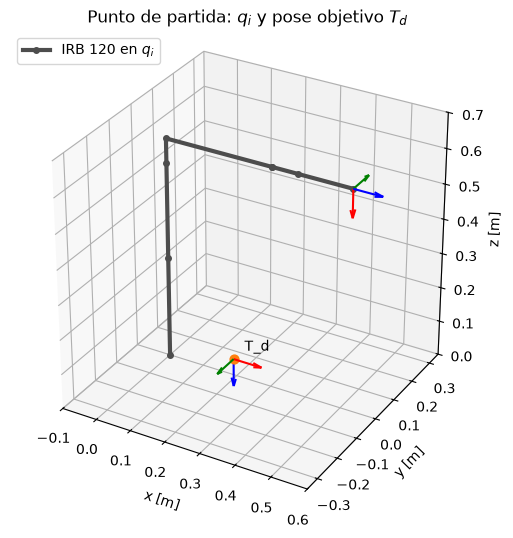

In [102]:
def ejes(ax, T, largo=0.08):
    for k, color in enumerate("rgb"):
        ax.quiver(*T[:3, 3], *(largo * T[:3, k]), color=color, linewidth=1.5)

fig = plt.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(projection="3d")
P = np.array([T[:3, 3] for T in F0])
ax.plot(P[:, 0], P[:, 1], P[:, 2], "-o", color="0.3", linewidth=3, markersize=4, label="IRB 120 en $q_i$")
ejes(ax, F0[-1])
ax.scatter(*T_D[:3, 3], color="tab:orange", s=40)
ax.text(*(T_D[:3, 3] + 0.02), NOMBRE)
ejes(ax, T_D)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_xlim(-0.1, 0.6); ax.set_ylim(-0.35, 0.35); ax.set_zlim(0, 0.7)
ax.set_box_aspect((0.7, 0.7, 0.7)); ax.legend(loc="upper left")
ax.set_title("Punto de partida: $q_i$ y pose objetivo $T_d$")
fig.tight_layout(); fig.savefig(FIG / "P1_punto_de_partida.png", dpi=150); fig.savefig(FIG / "P1_punto_de_partida.pdf")
plt.show()

In [103]:
cerrar_etapa("Modelo DH y FK", T_D=T_D, T_I=T_I, Q_I=Q_I)

■ Etapa 1 (Modelo DH y FK) cerrada: 6/6 verificaciones aprobadas
  entrega a la siguiente etapa: T_D, T_I, Q_I


## 2. Cinemática inversa analítica (método de Pieper)

> **Etapa 2.** **Entra:** `T_D` (etapa 1) · **Sale:** `RAMAS`, las 8 ramas candidatas, y el centro de muñeca `P_W`

### 2.1 Por qué existe solución cerrada: desacoplamiento

El teorema de Pieper garantiza solución cerrada para un 6R cuando **tres ejes consecutivos se cortan en un punto**.
En el IRB 120 los ejes 4, 5 y 6 se cortan en el **centro de muñeca** $W$ ($a_4 = a_5 = d_5 = 0$ en la tabla DH).
Eso separa el problema en dos:

- **Posición:** $W$ depende solo de $q_1, q_2, q_3$ (el brazo).
- **Orientación:** con el brazo resuelto, $q_4, q_5, q_6$ (la muñeca) completan $R_d$.

$W$ se obtiene retrocediendo desde el TCP a lo largo del eje de la herramienta $z_d$ (tercera columna de $R_d$) la
distancia muñeca-brida más la herramienta:

$$
p_W = p_d - (d_6 + d_{TCP})\,z_d = p_d - (0.072 + 0.150)\,z_d
$$

$W$ solo es alcanzable si su distancia al hombro $S = (0, 0, d_1)$ cumple
$|L_2 - L_3| \le \|W - S\| \le L_2 + L_3$, con $L_2 = a_2 = 0.270$ m y $L_3 = \sqrt{d_4^2 + a_3^2} = 0.3100$ m.

In [104]:
# ---- Entradas de la etapa 2 (cinemática inversa de Pieper y validación FK)
TOL_FK_POS_M = 1e-6        # m: tolerancia de posición de la validación FK
TOL_FK_ROT_RAD = 1e-6      # rad: tolerancia de orientación de la validación FK
pp.TOL_POS_M, pp.TOL_ROT_RAD = TOL_FK_POS_M, TOL_FK_ROT_RAD   # las ramas de Pieper se aceptan con estas

def pasa_fk(T_ref, T):
    """Criterio de aceptación FK de esta etapa: error de posición y de orientación bajo las tolerancias."""
    e_p, e_R = pp.errores_pose(T_ref, T)
    return e_p < TOL_FK_POS_M and e_R < TOL_FK_ROT_RAD
print(f"Entradas de la etapa 2: tolerancia FK = {TOL_FK_POS_M:.0e} m y {TOL_FK_ROT_RAD:.0e} rad")

Entradas de la etapa 2: tolerancia FK = 1e-06 m y 1e-06 rad


In [105]:
requiere("Modelo DH y FK")
print(f"L2 = {pp.L2:.4f} m,  L3 = {pp.L3:.4f} m,  delta = atan2(a3, d4) = {pp.DELTA:.4f} rad")
print(f"Alcance hombro-muñeca permitido: [{abs(pp.L2 - pp.L3):.4f}, {pp.L2 + pp.L3:.4f}] m\n")
P_W = pp.centro_muneca(T_D)
dist = np.linalg.norm(P_W - [0, 0, pp.D1])
print(f"{NOMBRE}: p_W = {P_W} m,  ||W - S|| = {dist:.4f} m")
verificar(f"{NOMBRE}: el centro de muñeca está dentro del alcance del brazo", abs(pp.L2 - pp.L3) <= dist <= pp.L2 + pp.L3)

L2 = 0.2700 m,  L3 = 0.3100 m,  delta = atan2(a3, d4) = 0.2278 rad
Alcance hombro-muñeca permitido: [0.0400, 0.5800] m

T_d: p_W = [ 0.25  -0.1    0.342] m,  ||W - S|| = 0.2742 m
✔ T_d: el centro de muñeca está dentro del alcance del brazo


### 2.2 Junta 1: fórmula de Pieper

$$q_1 = \operatorname{atan2}(P_{W,y}, P_{W,x})$$

### 2.3 Juntas 2 y 3: fórmulas de Pieper

Con $d_6 = 0.072 + \text{TCP} = 0.222$ m, el centro de muñeca es $P_W = P_d - d_6\,z_d$ y, en el plano del brazo:

$$r_{xy} = \sqrt{P_{W,x}^2 + P_{W,y}^2},\qquad z_{\text{brazo}} = P_{W,z} - d_1,\qquad A_{\text{eff}} = \sqrt{d_4^2 + a_3^2},\qquad \varphi = \operatorname{atan2}(d_4, a_3)$$

$$C_3 = \cos(q_3 + \varphi) = \frac{r_{xy}^2 + z_{\text{brazo}}^2 - a_2^2 - A_{\text{eff}}^2}{2 a_2 A_{\text{eff}}},\qquad S_3 = \pm\sqrt{1 - C_3^2}$$

$$q_1 = \operatorname{atan2}(P_{W,y}, P_{W,x}),\qquad q_3 = \operatorname{atan2}(S_3, C_3) - \varphi$$

$$q_2 = \operatorname{atan2}(r_{xy}, z_{\text{brazo}}) - \operatorname{atan2}\left(d_4 \cos q_3 + a_3 \sin q_3, a_2 + a_3 \cos q_3 - d_4 \sin q_3\right)$$

**Corrección de $q_2$:** En el cuadernillo, la fórmula de $q_2$ tiene los signos de $d_4$ invertidos. Con esa fórmula sale $q_2 = 0.4694$ rad y el centro de muñeca queda a $0.082$ m de $P_W$, así que no es solución. Por eso el compañero obtuvo otra $q_2$ y otra $q_5$. La fórmula de arriba sí reproduce $P_W$ exactamente.

### 2.4 Juntas 4, 5 y 6: fórmulas de Pieper (orientación de la muñeca)

$$R_3^6 = (R_0^3)^T R_d$$

$$q_5 = \operatorname{atan2}\left(\sqrt{r_{13}^2 + r_{23}^2}, r_{33}\right),\qquad q_4 = \operatorname{atan2}\left(\frac{r_{23}}{\sin q_5}, \frac{r_{13}}{\sin q_5}\right),\qquad q_6 = \operatorname{atan2}\left(\frac{r_{32}}{\sin q_5}, \frac{-r_{31}}{\sin q_5}\right) - \pi$$

### 2.5 Las 8 ramas de la pose objetivo

Para cada $T_d$ se enumeran **siempre las 8 ramas**, existan o no. La tabla indica:

- **real**: la rama existe geométricamente ($|k| \le 1$).
- **límites**: juntas que quedan fuera del rango del datasheet.
- **admisible**: es real, pasa la verificación FK (sección 3) y respeta todos los límites.

In [106]:
def tabla_ramas(nombre, candidatos):
    print(f"\n{nombre}")
    print(f"{'rama':>4} {'brazo':>9} {'codo':>7} {'muñeca':>6}  {'q1':>8} {'q2':>8} {'q3':>8} {'q4':>8} {'q5':>8} {'q6':>8}  {'real':>4} {'fuera de límites':>17} {'admisible':>9}")
    for c in candidatos:
        q = "  ".join(f"{v:8.4f}" for v in c.q) if c.real else f"{'— no existe (|k| = ' + f'{abs(c.k_codo):.3f}' + ' > 1) —':^58}"
        lim = ", ".join(f"q{j}" for j in c.fuera_de_limites) or "—"
        print(f"{c.rama:>4} {c.brazo:>9} {c.codo:>7} {c.muneca:>6}  {q}  {'sí' if c.real else 'no':>4} {lim:>17} {'SÍ' if c.admisible else 'no':>9}")

RAMAS = pp.pieper(T_D)
tabla_ramas(NOMBRE, RAMAS)
verificar(f"{NOMBRE}: se enumeran las 8 ramas", len(RAMAS) == 8)
print("\nÁngulos en radianes.")


T_d
rama     brazo    codo muñeca        q1       q2       q3       q4       q5       q6  real  fuera de límites admisible
   1    frente  arriba    q5+   -0.3805    0.1680    0.8225    0.0000    0.5802    2.7611    sí                 —        SÍ
   2    frente  arriba    q5-   -0.3805    0.1680    0.8225   -3.1416   -0.5802   -0.3805    sí                q4        no
   3    frente   abajo    q5+   -0.3805    2.5920    2.7746    0.0000    2.4874    2.7611    sí        q2, q3, q5        no
   4    frente   abajo    q5-   -0.3805    2.5920    2.7746   -3.1416   -2.4874   -0.3805    sí    q2, q3, q4, q5        no
   5  espaldas  arriba    q5+    2.7611   -0.1680    2.7746   -3.1416    1.0358    2.7611    sí            q3, q4        no
   6  espaldas  arriba    q5-    2.7611   -0.1680    2.7746    0.0000   -1.0358   -0.3805    sí                q3        no
   7  espaldas   abajo    q5+    2.7611   -2.5920    0.8225   -3.1416    2.9429    2.7611    sí        q2, q4, q5        no
   8  es

**Lectura de la tabla.** Las ramas vienen en pares que comparten brazo y codo y solo difieren en la muñeca: las
dos alcanzan la misma pose, una con $q_5$ positivo y otra con $q_5$ negativo y $q_4$, $q_6$ girados 180°. Las ramas
de espaldas necesitan $|q_1| > 165°$ o un hombro muy inclinado, por eso suelen violar límites. Que una rama sea real
pero no admisible no es un error de cálculo: es una postura que el robot no puede adoptar físicamente.

In [107]:
# ---- Fórmulas de Pieper del cuadernillo, contra el código (rama 1: frente-arriba-q5+)
Pw = P_W
r_xy = np.hypot(Pw[0], Pw[1]); z_brazo = Pw[2] - pp.D1
A_eff = np.hypot(pp.D4, pp.A3); phi = np.arctan2(pp.D4, pp.A3)
C3 = (r_xy**2 + z_brazo**2 - pp.L2**2 - A_eff**2) / (2 * pp.L2 * A_eff)
q1_f = np.arctan2(Pw[1], Pw[0])
q3_f = np.arctan2(np.sqrt(1 - C3**2), C3) - phi
q2_f = np.arctan2(r_xy, z_brazo) - np.arctan2(pp.D4 * np.cos(q3_f) + pp.A3 * np.sin(q3_f),
                                             pp.L2 + pp.A3 * np.cos(q3_f) - pp.D4 * np.sin(q3_f))
rama1 = RAMAS[0]
print(f"{NOMBRE}: r_xy = {r_xy:.4f} m,  z_brazo = {z_brazo:.4f} m,  A_eff = {A_eff:.4f} m,  Ï† = {phi:.4f} rad,  C3 = {C3:.4f}")
print(f"q1 = {q1_f:.4f},  q2 = {q2_f:.4f},  q3 = {q3_f:.4f} rad   (código, rama 1: {np.round(rama1.q[:3], 4)})")
verificar(f"{NOMBRE}: q1, q2, q3 del cuadernillo = código (rama 1)", np.allclose([q1_f, q2_f, q3_f], rama1.q[:3], atol=1e-9))
verificar(f"{NOMBRE}: la fórmula corregida de q2 reproduce P_W con q1, q2, q3", np.allclose(m.marcos(rama1.q)[4][:3, 3], Pw, atol=1e-9))
R36 = m.marcos(rama1.q)[3][:3, :3].T @ T_D[:3, :3]
q5_f = np.arctan2(np.hypot(R36[0, 2], R36[1, 2]), R36[2, 2])
verificar(f"{NOMBRE}: q5 = atan2(√(r13² + r23²), r33) = código (rama 1)", abs(q5_f - rama1.q[4]) < 1e-9)

T_d: r_xy = 0.2693 m,  z_brazo = 0.0520 m,  A_eff = 0.3100 m,  Ï† = 1.3430 rad,  C3 = -0.5603
q1 = -0.3805,  q2 = 0.1680,  q3 = 0.8225 rad   (código, rama 1: [-0.3805  0.168   0.8225])
✔ T_d: q1, q2, q3 del cuadernillo = código (rama 1)
✔ T_d: la fórmula corregida de q2 reproduce P_W con q1, q2, q3
✔ T_d: q5 = atan2(√(r13² + r23²), r33) = código (rama 1)


In [108]:
cerrar_etapa("Cinemática inversa (Pieper)", RAMAS=RAMAS, P_W=P_W)

■ Etapa 2 (Cinemática inversa (Pieper)) cerrada: 5/5 verificaciones aprobadas
  entrega a la siguiente etapa: RAMAS, P_W


## 3. Verificación por cinemática directa

> **Etapa 3.** **Entra:** `RAMAS` (etapa 2) · **Sale:** `ADMISIBLES`: ramas reales que reproducen `T_D` y respetan los límites

### 3.1 Criterio de aceptación

La IK se dedujo a mano, con ramas y envolturas de ángulo; un error de signo daría un $q$ que *parece* solución. Por eso
cada candidato real se **reinyecta en la FK** y se compara con la pose pedida, en posición **y** orientación:

$$
e_p = \|p(q^{(k)}) - p_d\| \;[\text{m}], \qquad
e_R = \angle\left(R_d^T R(q^{(k)})\right) = \operatorname{atan2}\!\left(\tfrac{\|\text{vee}(R - R^T)\|}{2},\ \tfrac{\operatorname{tr}R - 1}{2}\right) \;[\text{rad}]
$$

Se acepta si $e_p < 10^{-6}$ m y $e_R < 10^{-6}$ rad. Un micrómetro está muy por debajo de la repetibilidad del
IRB 120 (0.01 mm), así que cualquier error mayor sería un fallo de la deducción, no de redondeo.

In [109]:
requiere("Cinemática inversa (Pieper)")
print(f"\n{NOMBRE}")
print(f"{'rama':>4} {'e_p [m]':>10} {'e_R [rad]':>10} {'FK':>5} {'admisible':>9}")
for c in RAMAS:
    if c.real:
        print(f"{c.rama:>4} {c.e_pos_m:10.1e} {c.e_rot_rad:10.1e} {'pasa' if c.valida_fk else 'FALLA':>5} {'SÍ' if c.admisible else 'no':>9}")
    else:
        print(f"{c.rama:>4} {'—':>10} {'—':>10} {'—':>5} {'no':>9}")
reales = [c for c in RAMAS if c.real]
verificar(f"{NOMBRE}: las {len(reales)} ramas reales reproducen T_d (posición y orientación)", all(c.valida_fk for c in reales))
ADMISIBLES = [c.rama for c in RAMAS if c.admisible]
print(f"Ramas admisibles: {ADMISIBLES}")
verificar(f"{NOMBRE}: la pose es alcanzable (al menos una rama admisible)", len(ADMISIBLES) > 0)


T_d
rama    e_p [m]  e_R [rad]    FK admisible
   1    1.4e-16    2.9e-16  pasa        SÍ
   2    1.4e-16    3.7e-16  pasa        no
   3    1.7e-16    3.9e-16  pasa        no
   4    6.4e-17    3.8e-16  pasa        no
   5    8.3e-17    4.9e-17  pasa        no
   6    1.0e-16    1.2e-16  pasa        no
   7    1.1e-16    3.5e-16  pasa        no
   8    1.1e-16    2.5e-16  pasa        no
✔ T_d: las 8 ramas reales reproducen T_d (posición y orientación)
Ramas admisibles: [1]
✔ T_d: la pose es alcanzable (al menos una rama admisible)


In [110]:
# ---- Entrada de la etapa 3 (prueba de ida y vuelta)
SEMILLA_IDA_VUELTA = 0     # semilla de las 1000 configuraciones al azar (cambia la muestra, no la tarea)

### 3.2 Prueba independiente de ida y vuelta

Para comprobar la deducción en todo el espacio articular, no solo en la pose objetivo: se generan 1000
configuraciones $q$ aleatorias, se calcula $T = \text{FK}(q)$, se resuelve Pieper sobre $T$ y se exige que **una de
las 8 ramas sea el $q$ original** y que **todas** las ramas reales pasen la FK.

In [111]:
rng = np.random.default_rng(SEMILLA_IDA_VUELTA)
recuperadas, peor_p, peor_R, N = 0, 0.0, 0.0, 1000
for _ in range(N):
    q = rng.uniform(m.LIMITES_RAD[:, 0], m.LIMITES_RAD[:, 1])
    q[5] = rng.uniform(-np.pi, np.pi)          # q6 se compara módulo 2π
    cands = [c for c in pp.pieper(m.fk(q)) if c.real]
    if any(np.allclose(pp.envolver(c.q - q), 0, atol=1e-7) for c in cands):
        recuperadas += 1
    peor_p = max([peor_p] + [c.e_pos_m for c in cands])
    peor_R = max([peor_R] + [c.e_rot_rad for c in cands])
print(f"q original recuperado en {recuperadas}/{N} casos; peor e_p = {peor_p:.1e} m, peor e_R = {peor_R:.1e} rad")
verificar("ida y vuelta: Pieper recupera el q original en las 1000 configuraciones", recuperadas == N)
verificar("ida y vuelta: todas las ramas reales pasan la FK", peor_p < pp.TOL_POS_M and peor_R < pp.TOL_ROT_RAD)

# Caso singular: la pose inicial tiene q5 = 0. Pieper debe devolver q_i como una de sus ramas.
cands_i = pp.pieper(T_I)
print("\nPieper sobre T_i (muñeca singular):", [np.round(c.q, 4).tolist() for c in cands_i[:2]])
verificar("Pieper recupera q_i a partir de T_i pese a la singularidad de muñeca", any(np.allclose(pp.envolver(c.q - Q_I), 0, atol=1e-9) for c in cands_i if c.real))

q original recuperado en 1000/1000 casos; peor e_p = 7.3e-16 m, peor e_R = 1.3e-13 rad
✔ ida y vuelta: Pieper recupera el q original en las 1000 configuraciones
✔ ida y vuelta: todas las ramas reales pasan la FK

Pieper sobre T_i (muñeca singular): [[0.0, 0.0, -0.0, 0.0, 0.0, 0.0], [0.0, 0.0, -0.0, -3.1416, -0.0, -3.1416]]
✔ Pieper recupera q_i a partir de T_i pese a la singularidad de muñeca


### 3.3 Geometría de las ramas

Las 8 ramas se reducen a 4 posturas distintas del brazo (la muñeca no cambia la forma del brazo). En la figura, cada
línea es el robot en una rama real de la pose objetivo; las admisibles van en trazo continuo.

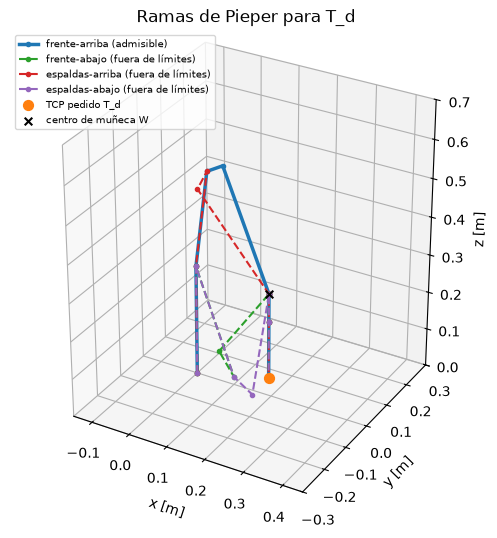

In [112]:
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
colores = {"frente-arriba": "tab:blue", "frente-abajo": "tab:green", "espaldas-arriba": "tab:red", "espaldas-abajo": "tab:purple"}
vistos = set()
for c in RAMAS:
    clave = f"{c.brazo}-{c.codo}"
    if not c.real or clave in vistos:
        continue
    vistos.add(clave)
    P = np.array([T[:3, 3] for T in m.marcos(c.q)])
    adm = any(o.admisible for o in RAMAS if o.brazo == c.brazo and o.codo == c.codo)
    ax.plot(P[:, 0], P[:, 1], P[:, 2], "-" if adm else "--", marker="o", markersize=3, linewidth=2.5 if adm else 1.5,
            color=colores[clave], label=f"{clave} ({'admisible' if adm else 'fuera de límites'})")
ax.scatter(*T_D[:3, 3], color="tab:orange", s=50, label=f"TCP pedido {NOMBRE}")
ax.scatter(*P_W, color="k", s=30, marker="x", label="centro de muñeca W")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_xlim(-0.15, 0.45); ax.set_ylim(-0.3, 0.3); ax.set_zlim(0, 0.7)
ax.set_box_aspect((0.6, 0.6, 0.7)); ax.legend(loc="upper left", fontsize=7)
ax.set_title(f"Ramas de Pieper para {NOMBRE}")
fig.tight_layout(); fig.savefig(FIG / "P2_ramas_pieper.png", dpi=150); fig.savefig(FIG / "P2_ramas_pieper.pdf")
plt.show()

In [113]:
cerrar_etapa("Verificación FK", RAMAS=RAMAS, ADMISIBLES=ADMISIBLES)

■ Etapa 3 (Verificación FK) cerrada: 5/5 verificaciones aprobadas
  entrega a la siguiente etapa: RAMAS, ADMISIBLES


## 4. Selección de la configuración final $q_f$

> **Etapa 4.** **Entra:** `RAMAS` verificadas (etapa 3) y `Q_I` · **Sale:** `Q_F`, la configuración final elegida y justificada


No es lo mismo que la sección 3. La sección 3 responde **"¿la rama es correcta?"**: reinyecta cada candidato en la
FK. La sección 4 responde **"¿cuál de las correctas uso para mover el robot?"**. Como todas las ramas reales ya
pasaron la FK, la elección es un criterio **físico y práctico**, y la guía pide justificarla. La plantilla
(`seleccion_ramas.py`) trabaja en dos etapas:

**Etapa 1. Filtros obligatorios.** No se recalcula nada: se **reutiliza** lo que ya salió de las secciones 2.5 y 3
(los atributos `real`, `valida_fk` y `fuera_de_limites` de cada rama). Una rama que falla un filtro queda descartada
con puntaje 0, y se escribe el valor que la descartó.

| Filtro | Viene de | Condición |
|---|---|---|
| F1 real | sección 2.3 | $|k| \le 1$ |
| F2 FK | sección 3 | $e_p < 10^{-6}$ m y $e_R < 10^{-6}$ rad |
| F3 límites | sección 2.5 | $q_{j,\min} \le q_j \le q_{j,\max}$ (datasheet ABB) |

**Etapa 2. Índices de calidad** (cada uno de 0 = peor a 1 = mejor) y puntaje:

| Índice | Fórmula | Qué premia | Peso |
|---|---|---|---|
| $I_{lim}$ | $\min_j \dfrac{\min(q_j - q_{j,\min},\ q_{j,\max} - q_j)}{(q_{j,\max} - q_{j,\min})/2}$ | juntas lejos de sus topes | 0.25 |
| $I_{sing}$ | $|\sin q_5|$ | muñeca lejos de la singularidad $q_5 = 0$ | 0.25 |
| $I_{esp}$ | $\min\!\left(1,\ \dfrac{\min(z_{codo}, z_W)}{0.20\ \text{m}}\right)$ | codo y muñeca lejos de la mesa ($z = 0$) | 0.15 |
| $I_{mov}$ | $1 - \dfrac{\|W(q - q_i)\|}{\|W\pi\|}$, $W = \text{diag}(1,1,1,0.5,0.5,0.5)$ | menor movimiento desde $q_i$, más peso al brazo | 0.35 |

$$
\text{Puntaje} = 100\,\left(0.25\,I_{lim} + 0.25\,I_{sing} + 0.15\,I_{esp} + 0.35\,I_{mov}\right) \in [0, 100]
$$

Se elige la rama admisible de **mayor puntaje**. Los pesos son una decisión de diseño declarada: el movimiento pesa más
porque define la duración y el esfuerzo de la trayectoria LSPB. Para $q_6$ (rango ±400°) se usa el representante
$q_6 + 2\pi k$ más cercano a $q_i$.

In [114]:
# ---- Entrada de la etapa 4 (selección de q_f)
PESOS = {"I_lim": 0.25, "I_sing": 0.25, "I_esp": 0.15, "I_mov": 0.35}   # adimensional; deben sumar 1
assert abs(sum(PESOS.values()) - 1.0) < 1e-12, "los pesos del puntaje deben sumar 1"
sel.PESOS = dict(PESOS)
print("Entradas de la etapa 4: pesos del puntaje", PESOS)

Entradas de la etapa 4: pesos del puntaje {'I_lim': 0.25, 'I_sing': 0.25, 'I_esp': 0.15, 'I_mov': 0.35}


In [115]:
requiere("Verificación FK")
FILAS, ELEGIDA = sel.evaluar(RAMAS, Q_I)
sel.imprimir(NOMBRE, FILAS)
verificar(f"{NOMBRE}: hay una configuración elegida", ELEGIDA is not None)
Q_F = ELEGIDA["q"]
print(f"\n  → q_f({NOMBRE}) = {np.round(Q_F, 4)} rad  (rama {ELEGIDA['rama']}, {ELEGIDA['puntaje']:.1f} puntos)")
# Única FK nueva de esta sección: q6 puede haberse cambiado por q6 ± 360° (otro representante del mismo ángulo).
verificar(f"{NOMBRE}: q_f con su representante de q6 sigue reproduciendo T_d", pasa_fk(T_D, m.fk(Q_F)))


T_d
rama configuración           F1  F2  F3  I_lim I_sing I_esp I_mov  puntaje  estado    
--------------------------------------------------------------------------------------
   1 frente-arriba-q5+       sí  sí  sí   0.25    0.55   1.00   0.72     60.4  ELEGIDA   
   2 frente-arriba-q5-       sí  sí  no   0.00    0.55   1.00   0.70      0.0  descartada
   3 frente-abajo-q5+        sí  sí  no   0.00    0.61   0.30   0.30      0.0  descartada
   4 frente-abajo-q5-        sí  sí  no   0.00    0.61   0.30   0.29      0.0  descartada
   5 espaldas-arriba-q5+     sí  sí  no   0.00    0.86   1.00   0.27      0.0  descartada
   6 espaldas-arriba-q5-     sí  sí  no   0.00    0.86   1.00   0.35      0.0  descartada
   7 espaldas-abajo-q5+      sí  sí  no   0.00    0.20   0.30   0.24      0.0  descartada
   8 espaldas-abajo-q5-      sí  sí  no   0.00    0.20   0.30   0.32      0.0  descartada

Motivo de cada decisión:
  rama 1: mayor puntaje entre las admisibles
  rama 2: F3: q4 = -180.0° fue

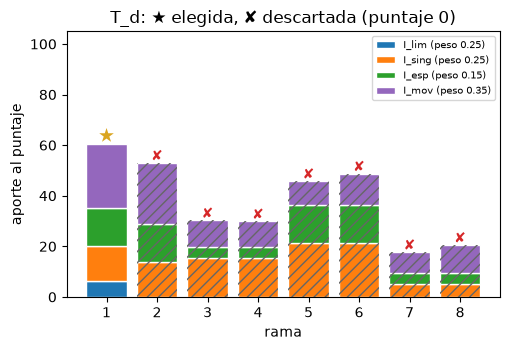

Las barras rayadas muestran cuánto sumarían los índices si la rama no estuviera descartada por un filtro.


In [116]:
# Gráfica de la plantilla: aporte de cada índice al puntaje (usa FILAS y ELEGIDA de la celda anterior).
fig, ax = plt.subplots(figsize=(5.2, 3.6))
colores = {"I_lim": "tab:blue", "I_sing": "tab:orange", "I_esp": "tab:green", "I_mov": "tab:purple"}
x = np.arange(1, 9)
base = np.zeros(8)
for k, w in sel.PESOS.items():
    v = np.array([100 * w * f["indices"][k] if f["indices"] else 0.0 for f in FILAS])
    ax.bar(x, v, bottom=base, color=colores[k], label=f"{k} (peso {w})", edgecolor="white")
    base += v
for f in FILAS:
    if f["estado"] == "descartada":
        ax.bar(f["rama"], base[f["rama"] - 1], fill=False, hatch="///", edgecolor="0.4", linewidth=0)
        ax.text(f["rama"], base[f["rama"] - 1] + 1, "✘", ha="center", color="tab:red")
ax.text(ELEGIDA["rama"], base[ELEGIDA["rama"] - 1] + 1, "★", ha="center", fontsize=14, color="goldenrod")
ax.set_xticks(x); ax.set_xlabel("rama"); ax.set_ylabel("aporte al puntaje"); ax.set_ylim(0, 105)
ax.set_title(f"{NOMBRE}: ★ elegida, ✘ descartada (puntaje 0)")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "P3_seleccion_ramas.png", dpi=150); fig.savefig(FIG / "P3_seleccion_ramas.pdf")
plt.show()
print("Las barras rayadas muestran cuánto sumarían los índices si la rama no estuviera descartada por un filtro.")

In [117]:
cerrar_etapa("Selección de q_f", Q_F=Q_F)

■ Etapa 4 (Selección de q_f) cerrada: 2/2 verificaciones aprobadas
  entrega a la siguiente etapa: Q_F


## 5. Trayectoria LSPB de $q_i$ a $q_f$

> **Etapa 5.** **Entra:** `Q_I` y `Q_F` (etapa 4), `VMAX`, `AMAX` · **Sale:** `TR` y su muestreo único `t_tr, q_tr, qd_tr, qdd_tr`, que usan las etapas 6 y 7


Pieper entrega solo el destino $q_f$. Dos configuraciones no definen *cómo* moverse: hace falta una **trayectoria**
parametrizada en el tiempo, $q(t),\ \dot q(t),\ \ddot q(t)$, porque de ella dependen la velocidad, la aceleración y,
más adelante, el torque de los motores (*W09-S01, diapositiva 7*).

### 5.1 Ecuaciones de clase (una junta)

El LSPB (*Linear Segment with Parabolic Blends*) da un perfil de velocidad **trapezoidal**: arranca con aceleración
constante $\ddot q_c$, sigue a velocidad constante $\dot q_c$ y frena con $-\ddot q_c$. Supuestos: reposo en los
extremos $\dot q(0) = \dot q(t_f) = 0$ (*W09-S01, diapositiva 8*):

| Fase | Intervalo | $q(t)$ | $\dot q(t)$ | $\ddot q(t)$ |
|---|---|---|---|---|
| 1. Aceleración | $0 \le t \le t_c$ | $q_i + \tfrac12 \ddot q_c t^2$ | $\ddot q_c\, t$ | $\ddot q_c$ |
| 2. Vel. constante | $t_c < t \le t_f - t_c$ | $q_i + \dot q_c\,(t - \tfrac{t_c}{2})$ | $\dot q_c = \ddot q_c t_c$ | $0$ |
| 3. Desaceleración | $t_f - t_c < t \le t_f$ | $q_f - \tfrac12 \ddot q_c (t_f - t)^2$ | $\ddot q_c (t_f - t)$ | $-\ddot q_c$ |

Tiempo de mezcla y condición de factibilidad (*W09-S01, diapositiva 9; hoja de trabajo LSPB W09-S01*):

$$
t_c = \frac{t_f}{2} - \frac12\sqrt{t_f^2 - \frac{4(q_f - q_i)}{\ddot q_c}},
\qquad
|\ddot q_c| \ge \frac{4\,|q_f - q_i|}{t_f^2}
$$

Con la igualdad desaparece el tramo de velocidad constante y el perfil de velocidad es triangular. $q$ y $\dot q$ son
continuas; $\ddot q$ tiene saltos en $t_c$ y $t_f - t_c$, lo que es aceptable en el modelo básico (*hoja de trabajo
LSPB, parte B*).

**Comprobación con el ejemplo guiado de clase** ($q_i = 0$, $q_f = 2$ rad, $t_f = 3$ s, $\ddot q_c = 1$ rad/s²): la
diapositiva 10 da $|\ddot q_c|_{\min} = 8/9$, $t_c = 1$ s y $\dot q_c = 1$ rad/s.

In [118]:
requiere("Selección de q_f")
a_min = lspb.aceleracion_minima(0.0, 2.0, 3.0)
tc_ej = lspb.tiempo_mezcla(0.0, 2.0, 3.0, 1.0)
print(f"|q̈c|_min = {a_min:.4f} rad/s² (8/9 = {8/9:.4f}),  tc = {tc_ej:.4f} s,  q̇c = q̈c·tc = {1.0 * tc_ej:.4f} rad/s")
verificar("el código reproduce el ejemplo guiado de clase (tc = 1 s, q̇c = 1 rad/s)", np.isclose(a_min, 8/9) and np.isclose(tc_ej, 1.0))

|q̈c|_min = 0.8889 rad/s² (8/9 = 0.8889),  tc = 1.0000 s,  q̇c = q̈c·tc = 1.0000 rad/s
✔ el código reproduce el ejemplo guiado de clase (tc = 1 s, q̇c = 1 rad/s)


### 5.2 Seis juntas sincronizadas

La clase trata una sola junta. El robot mueve las seis a la vez y deben **empezar y terminar juntas**, si no el TCP
seguiría un camino raro y cada motor terminaría en un instante distinto. Se usa la extensión estándar
(Siciliano et al., 2009, sec. 4.2.1): **mismo $t_f$ y mismo $t_c$ para todas**, y cada junta ajusta su
$\ddot q_c$.

1. **Tiempo mínimo de cada junta** con su $v_{\max}$ y $a_{\max}$. Si $|D| \ge v_{\max}^2 / a_{\max}$ alcanza la
   velocidad máxima (trapecio) y $t_{f,j} = |D|/v_{\max} + v_{\max}/a_{\max}$; si no, el perfil es triangular y
   $t_{f,j} = 2\sqrt{|D|/a_{\max}}$, con $D = q_f - q_i$.
2. **Junta crítica:** la de mayor $t_{f,j}$. Ella fija $t_f$ (redondeado hacia arriba a 0.01 s).
3. **Tiempo de mezcla común** con la fórmula de clase, usando en la junta crítica su $\ddot q_c = a_{\max}$.
4. **Cada junta:** al exigir que la posición sea continua en $t = t_f - t_c$ (fin del tramo 2 = inicio del tramo 3):

$$
q_i + \dot q_c\left(t_f - \tfrac{3t_c}{2}\right) = q_f - \tfrac12 \ddot q_c t_c^2
\;\;\xrightarrow{\ \dot q_c = \ddot q_c t_c\ }\;\;
D = \ddot q_c\, t_c\,(t_f - t_c)
\;\;\Rightarrow\;\;
\dot q_c = \frac{D}{t_f - t_c},\qquad \ddot q_c = \frac{\dot q_c}{t_c}
$$

Como las demás juntas recorren menos en el mismo tiempo, sus $\dot q_c$ y $\ddot q_c$ quedan por debajo de sus
límites.

### 5.3 Límites y supuestos

- $v_{\max}$: datasheet ABB por eje (250, 250, 250, 320, 320, 420 °/s), al **25 %**, como un *override* de velocidad
  conservador para pruebas.
- $a_{\max}$: **ABB no publica aceleraciones articulares.** Supuesto declarado: cada eje alcanza su $v_{\max}$ en
  $0.25$ s, es decir $a_{\max} = v_{\max} / 0.25$ s. Se declaran en la etapa 5 (`ESCALA_VEL`, `T_RAMPA_S`).

In [119]:
# ---- Entradas de la etapa 5 (trayectoria LSPB)
ESCALA_VEL = 0.25          # adimensional: fracción de la velocidad del datasheet ABB
T_RAMPA_S = 0.25           # s: tiempo para llegar a v_max; a_max = v_max / T_RAMPA_S (supuesto, ABB no publica aceleraciones)
N_TRAY = 1201              # muestras de q(t) que usan las etapas 6 y 7
N_AREA = 20001             # rejilla fina solo para verificar que el área bajo q̇(t) es D
TF_S = 3               # s: tiempo total elegido. None = usar el t_f,min calculado abajo (redondeado a 0.01 s).
                          # Si se escribe un valor, debe ser >= t_f,min; si no, la celda se detiene con un mensaje.
TC_S = 0.8               # s: tiempo de mezcla elegido. None = fórmula de clase con a_max; si se escribe, t_f se calcula como el mínimo compatible.
VMAX = ESCALA_VEL * m.VMAX_RAD_S     # rad/s
AMAX = VMAX / T_RAMPA_S              # rad/s²

#### Deducción del tiempo mínimo $t_{f,\min}$

Con $D_j = |q_{f,j} - q_{i,j}|$, $v_{\max,j}$ y $a_{\max,j}$ de cada junta, el menor tiempo que puede tardar esa junta es:

$$
t_{f,j} = \begin{cases}
\dfrac{D_j}{v_{\max,j}} + \dfrac{v_{\max,j}}{a_{\max,j}}, & \text{si } D_j \ge \dfrac{v_{\max,j}^2}{a_{\max,j}} \quad\text{(perfil trapezoidal: llega a } v_{\max}) \\[2ex]
2\sqrt{\dfrac{D_j}{a_{\max,j}}}, & \text{en otro caso} \quad\text{(perfil triangular)}
\end{cases}
$$

El tiempo de todo el movimiento lo fija la junta más lenta, la **junta crítica**:

$$
t_{f,\min} = \max_j t_{f,j}
$$

Como las seis juntas deben llegar juntas, se usa ese $t_{f,\min}$ para todas. Por defecto se redondea hacia arriba a 0.01 s. Si se escribe `TF_S`, la trayectoria usa ese valor, que debe ser mayor o igual a $t_{f,\min}$.

Con los valores por defecto da:

| Junta | $\lvert D\rvert$ [°] | $v_{\max}$ [°/s] | $a_{\max}$ [°/s²] | Perfil | $t_{f,j}$ [s] |
|---|---:|---:|---:|---|---:|
| q1 | 21.80 | 62.5 | 250.0 | trapecio | 0.5988 |
| q2 | 9.63 | 62.5 | 250.0 | triangular | 0.3925 |
| q3 | 47.13 | 62.5 | 250.0 | trapecio | 1.0041 |
| q4 | 0.00 | 80.0 | 320.0 | reposo | 0.0000 |
| q5 | 33.24 | 80.0 | 320.0 | trapecio | 0.6656 |
| **q6** | 158.20 | 105.0 | 420.0 | trapecio | **1.7567** (crítica) |

Así, $t_{f,\min} = 1.7567$ s, fijado por **q6**. Redondeado hacia arriba a 0.01 s da $t_f = 1.76$ s.

#### Deducción de $a_{\max}$ (supuesto de la rampa)

ABB no publica aceleraciones articulares. Por eso $a_{\max}$ se **supone** a partir de la velocidad máxima y del tiempo
que tarda una junta en alcanzarla:

$$
a_{\max,j} = \frac{v_{\max,j}}{T_{\text{rampa}}}, \qquad T_{\text{rampa}} = 0.25\ \text{s (supuesto)}
$$

Es la **pendiente de la rampa de velocidad**: la junta pasa de 0 a $v_{\max}$ en $T_{\text{rampa}}$ segundos
($a = \Delta v / \Delta t$). Con $v_{\max}$ del 25 % del datasheet, $a_{\max}$ para q6 es $105\ °/\text{s} / 0.25\ \text{s} = 420\ °/\text{s}^2$.

**De dónde sale $t_c$.** En el LSPB, la junta acelera con $\ddot q_c$ durante $t_c$ segundos hasta llegar a
$\dot q_c = \ddot q_c\, t_c$, que es la velocidad de crucero. Como $\ddot q_c$ de la junta crítica vale $a_{\max}$,
el tiempo de mezcla es la fórmula de clase:

$$
t_c = \frac{t_f}{2} - \frac12\sqrt{t_f^2 - \frac{4\,D}{a_{\max}}}
$$

El tramo a velocidad constante es $t_f - 2\,t_c$. Así, si $a_{\max}$ sube, $t_c$ baja y el crucero se alarga. Además,
$a_{\max}$ entra en el tiempo mínimo $t_{f,j} = D/v_{\max} + v_{\max}/a_{\max}$, así que también cambia $t_f$.

**Efecto de $T_{\text{rampa}}$ en q6** (las demás entradas por defecto, $v_{\max} = 105\ °/\text{s}$, $D = 158.20°$):

| $T_{\text{rampa}}$ [s] | $a_{\max}$ q6 [°/s²] | $t_{f,\min}$ [s] | $t_f$ usado [s] | $t_c$ [s] | Crucero $t_f - 2t_c$ [s] |
|---:|---:|---:|---:|---:|---:|
| 0.25 (por defecto) | 420.0 | 1.7567 | 1.76 | 0.2493 | 1.2613 |
| 0.50 | 210.0 | 2.0067 | 2.01 | 0.4984 | 1.0133 |

Al duplicar $T_{\text{rampa}}$, la aceleración se reduce a la mitad, el movimiento dura más y el crucero se acorta.

> **Importante:** $T_{\text{rampa}} = 0.25$ s es un **supuesto de este trabajo**, no un dato de ABB. Para cambiarlo, edita
> `T_RAMPA_S` en la etapa 5. Debe justificarse en el informe.

### 5.4 Parámetros de la trayectoria

Para la pose objetivo se planifica el movimiento desde la configuración inicial $q_i$ hasta el $q_f$ elegido en la
sección 4. La tabla documenta lo que pide la guía: configuración inicial y final, tiempo total, aceleración y tiempo
de mezcla de cada junta.

In [120]:
TR = lspb.LSPB(Q_I, Q_F, vmax=VMAX, amax=AMAX, tf=TF_S, tc=TC_S)
print(f"\n{NOMBRE}:  t_f = {TR.tf:.2f} s,  t_c = {TR.tc:.4f} s,  tramo a vel. constante = {TR.tf - 2 * TR.tc:.4f} s,  junta crítica = q{TR.critica + 1}")
print(f"{'junta':>5} {'q_i [rad]':>10} {'q_f [rad]':>10} {'D [rad]':>10} {'t_f,j min [s]':>13} {'|q̈c|min [rad/s²]':>17} {'q̈c [rad/s²]':>12} {'t_c fórmula [s]':>15} {'q̇c [rad/s]':>11} {'q̇c/vmax':>8} {'q̈c/amax':>8}")
for j in range(6):
    D = TR.D[j]
    tc_j = lspb.tiempo_mezcla(TR.q_i[j], TR.q_f[j], TR.tf, TR.qdd_c[j]) if D != 0 else float("nan")
    print(f"{'q' + str(j+1):>5} {TR.q_i[j]:10.4f} {TR.q_f[j]:10.4f} {D:10.4f} {TR.tf_min[j]:13.4f} "
          f"{lspb.aceleracion_minima(TR.q_i[j], TR.q_f[j], TR.tf):17.4f} {TR.qdd_c[j]:12.4f} {tc_j:15.4f} "
          f"{TR.qd_c[j]:11.4f} {abs(TR.qd_c[j]) / TR.vmax[j]:8.3f} {abs(TR.qdd_c[j]) / TR.amax[j]:8.3f}")

# Muestreo único de la trayectoria: es la entrada de las etapas 6 (Jacobiano) y 7 (dinámica).
t_tr, q_tr, qd_tr, qdd_tr = TR.muestrear(N_TRAY)
print(f"\nTrayectoria muestreada: {len(t_tr)} instantes entre 0 y {TR.tf:.2f} s (paso {t_tr[1] - t_tr[0]:.4f} s)")


T_d:  t_f = 3.00 s,  t_c = 0.8000 s,  tramo a vel. constante = 1.4000 s,  junta crítica = q6
junta  q_i [rad]  q_f [rad]    D [rad] t_f,j min [s] |q̈c|min [rad/s²] q̈c [rad/s²] t_c fórmula [s] q̇c [rad/s] q̇c/vmax q̈c/amax
   q1     0.0000    -0.3805    -0.3805        0.5988            0.1691      -0.2162          0.8000     -0.1730    0.159    0.050
   q2     0.0000     0.1680     0.1680        0.3925            0.0747       0.0955          0.8000      0.0764    0.070    0.022
   q3     0.0000     0.8225     0.8225        1.0041            0.3656       0.4674          0.8000      0.3739    0.343    0.107
   q4     0.0000     0.0000     0.0000        0.0000            0.0000       0.0000             nan      0.0000    0.000    0.000
   q5     0.0000     0.5802     0.5802        0.6656            0.2579       0.3297          0.8000      0.2637    0.189    0.059
   q6     0.0000     2.7611     2.7611        1.7567            1.2271       1.5688          0.8000      1.2550    0.685    0.

**Lectura de la tabla.** La junta crítica es la que más tarda con sus propios límites; usa casi el 100 % de su
$v_{\max}$ y su $a_{\max}$. Las demás se estiran al mismo $t_f$ y usan una fracción de sus límites. La columna
"$t_c$ fórmula" aplica la ecuación de clase a cada junta con su propio $\ddot q_c$ y devuelve el mismo $t_c$ para
todas, lo que confirma la sincronización. En cada junta $|\ddot q_c| \ge |\ddot q_c|_{\min}$, así que el perfil existe.

### 5.5 Perfiles $q(t)$, $\dot q(t)$, $\ddot q(t)$ alineados

Las tres gráficas comparten el eje de tiempo para leer las fases en vertical (*matriz diagnóstica W10-S01*: "alinee los
gráficos de $q$, $\dot q$, $\ddot q$"). Las bandas marcan las fases: aceleración, velocidad constante y desaceleración.
Es la **velocidad** la que tiene forma de trapecio, no la posición.

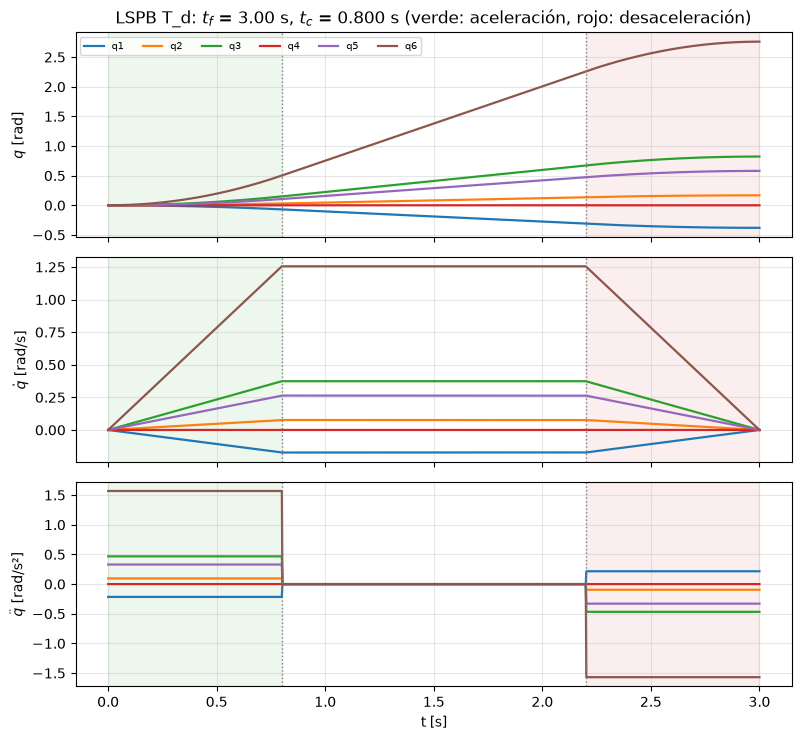

In [121]:
fig, axs = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
datos = [(q_tr, "$q$ [rad]"), (qd_tr, r"$\dot q$ [rad/s]"), (qdd_tr, r"$\ddot q$ [rad/s²]")]
for ax, (yv, etiqueta) in zip(axs, datos):
    for j in range(6):
        ax.plot(t_tr, yv[:, j], color=plt.cm.tab10(j), linewidth=1.6, label=f"q{j+1}")
    ax.axvspan(0, TR.tc, color="tab:green", alpha=0.08)
    ax.axvspan(TR.tf - TR.tc, TR.tf, color="tab:red", alpha=0.08)
    for xv in (TR.tc, TR.tf - TR.tc):
        ax.axvline(xv, color="0.5", linestyle=":", linewidth=1)
    ax.set_ylabel(etiqueta); ax.grid(alpha=0.3)
axs[0].legend(ncol=6, fontsize=7, loc="upper left")
axs[0].set_title(f"LSPB {NOMBRE}: $t_f$ = {TR.tf:.2f} s, $t_c$ = {TR.tc:.3f} s (verde: aceleración, rojo: desaceleración)")
axs[2].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(FIG / f"P5_lspb_{NOMBRE}.png", dpi=150); fig.savefig(FIG / f"P5_lspb_{NOMBRE}.pdf")
plt.show()

### 5.6 Verificaciones

La guía exige validar las **condiciones de frontera** (reposo al inicio y al final). Además se comprueba la
continuidad, los límites, que el área bajo $\dot q(t)$ sea el desplazamiento y que el robot termine en $T_d$.

In [122]:
q0, qd0, _ = TR.evaluar(0.0)
q1, qd1, _ = TR.evaluar(TR.tf)
verificar(f"{NOMBRE}: q(0) = q_i y q(t_f) = q_f", np.allclose(q0, TR.q_i, atol=1e-12) and np.allclose(q1, TR.q_f, atol=1e-12))
verificar(f"{NOMBRE}: reposo en las fronteras, qÌ‡(0) = qÌ‡(t_f) = 0", np.allclose(qd0, 0, atol=1e-12) and np.allclose(qd1, 0, atol=1e-12))
eps, salto_q, salto_qd = 1e-9, 0.0, 0.0
for tk in (TR.tc, TR.tf - TR.tc):
    a, b = TR.evaluar(tk - eps), TR.evaluar(tk + eps)
    salto_q, salto_qd = max(salto_q, np.abs(a[0] - b[0]).max()), max(salto_qd, np.abs(a[1] - b[1]).max())
verificar(f"{NOMBRE}: q y q̇ continuas en t_c y t_f − t_c (saltos {salto_q:.1e}, {salto_qd:.1e})", salto_q < 1e-6 and salto_qd < 1e-6)
verificar(f"{NOMBRE}: |q̇c| ≤ vmax y |q̈c| ≤ amax en las 6 juntas",
          np.all(np.abs(TR.qd_c) <= TR.vmax + 1e-12) and np.all(np.abs(TR.qdd_c) <= TR.amax + 1e-12))
verificar(f"{NOMBRE}: |q̈c| ≥ 4|D|/t_f² en cada junta (el perfil existe)",
          np.all(np.abs(TR.qdd_c) >= lspb.aceleracion_minima(TR.q_i, TR.q_f, TR.tf) - 1e-12))
verificar(f"{NOMBRE}: t_c ≤ t_f / 2", TR.tc <= TR.tf / 2)
t_a, _, qd_a, _ = TR.muestrear(N_AREA)          # rejilla fina solo para la integral
area = np.sum((qd_a[1:] + qd_a[:-1]) / 2 * np.diff(t_a)[:, None], axis=0)
verificar(f"{NOMBRE}: el área bajo q̇(t) es el desplazamiento D (error {np.abs(area - TR.D).max():.1e} rad)", np.allclose(area, TR.D, atol=1e-6))
verificar(f"{NOMBRE}: el TCP termina en T_d", pasa_fk(T_D, m.fk(q1)))

✔ T_d: q(0) = q_i y q(t_f) = q_f
✔ T_d: reposo en las fronteras, qÌ‡(0) = qÌ‡(t_f) = 0
✔ T_d: q y q̇ continuas en t_c y t_f − t_c (saltos 2.5e-09, 1.6e-09)
✔ T_d: |q̇c| ≤ vmax y |q̈c| ≤ amax en las 6 juntas
✔ T_d: |q̈c| ≥ 4|D|/t_f² en cada junta (el perfil existe)
✔ T_d: t_c ≤ t_f / 2
✔ T_d: el área bajo q̇(t) es el desplazamiento D (error 7.8e-09 rad)
✔ T_d: el TCP termina en T_d


In [123]:
cerrar_etapa("Trayectoria LSPB", TR=TR, t_tr=t_tr, q_tr=q_tr, qd_tr=qd_tr, qdd_tr=qdd_tr)

■ Etapa 5 (Trayectoria LSPB) cerrada: 9/9 verificaciones aprobadas
  entrega a la siguiente etapa: TR, t_tr, q_tr, qd_tr, qdd_tr


## 6. Jacobiano geométrico y singularidades

> **Etapa 6.** **Entra:** `Q_F` (etapa 4), `TR` y su muestreo (etapa 5) · **Sale:** `J_f`, el twist del TCP y `rangos` de $J$ en cada instante de la trayectoria


El Jacobiano relaciona las velocidades articulares con la **velocidad espacial (twist)** del TCP: velocidad lineal
arriba y angular abajo, las dos en el marco base (*W08-S01, diapositivas 2 y 5*, convención de Siciliano et al.):

$$
\dot x = \begin{bmatrix} v \\ \omega \end{bmatrix} = J(q)\,\dot q, \qquad J \in \mathbb{R}^{6\times 6}
$$

Lo que pide la guía (*Guía oficial Hito 2, sec. 3.3* y rúbrica D, 20 %): implementar $\dot x = J(q)\dot q$; un
**experimento computacional independiente** con una secuencia de poses hacia una singularidad conocida; **registrar
la pérdida de rango** $\operatorname{rank}J(q) < \operatorname{rank}_{\max}$, **graficarla**, **interpretar la movilidad
perdida** y **analizar la amplificación de velocidad**. Excelencia: "experimento de aproximación claro; interpreta
rango y movilidad perdida".

Todo se evalúa sobre la misma $T_d$, su $q_f$ y la trayectoria LSPB de la sección 5.

In [124]:
requiere("Selección de q_f", "Trayectoria LSPB")
print("q_f [rad] =", np.round(Q_F, 4))

q_f [rad] = [-0.3805  0.168   0.8225  0.      0.5802  2.7611]


In [125]:
# ---- Entradas de la etapa 6 (Jacobiano y singularidades)
TOL_RANGO = 1e-6           # adimensional: σ_i por debajo de esto cuenta como cero (rango numérico)
SEMILLA_JACOBIANO = 6      # semilla de las posturas al azar de la verificación del Jacobiano
print(f"Entradas de la etapa 6: umbral de rango Ïƒ > {TOL_RANGO:.0e},  semilla = {SEMILLA_JACOBIANO}")

Entradas de la etapa 6: umbral de rango Ïƒ > 1e-06,  semilla = 6


### 6.1 Construcción columna a columna

Si solo gira la junta $i$ (de revolución), el robot desde ese eslabón en adelante rota como un sólido rígido
alrededor del eje $z_{i-1}$, que pasa por $o_{i-1}$. La velocidad del TCP es $\omega_i\times r_i$ con
$r_i = p_{TCP} - o_{i-1}$ (*W08-S01, diapositivas 6 y 7*; Siciliano et al., 2009, sec. 3.1.3):

$$
J_i = \begin{bmatrix} J_{v,i} \\ J_{\omega,i}\end{bmatrix} = \begin{bmatrix} z_{i-1}\times(p_{TCP} - o_{i-1}) \\ z_{i-1}\end{bmatrix},
\qquad \dot x = \sum_{i=1}^{6} J_i\,\dot q_i
$$

$z_{i-1}$ es la tercera columna de $R_0^{i-1}$ y $o_{i-1}$ la traslación de $T_0^{i-1}$; los dos salen de la misma
FK de la sección 1 (`m.marcos(q)`), así que **todos los vectores están en el marco base {0}**, como exige la regla de
marcos del producto cruz (*W08-S02, diapositiva 3*). Código: `jacobiano.py`, función `jacobiano(q)`.

In [126]:
J_f = jb.jacobiano(Q_F)
print("J(q_f)  (filas: vx vy vz [m/s], wx wy wz [rad/s]; columnas: qÌ‡1..qÌ‡6 en rad/s)\n")
print(np.round(J_f, 4))

J(q_f)  (filas: vx vy vz [m/s], wx wy wz [rad/s]; columnas: qÌ‡1..qÌ‡6 en rad/s)

[[ 0.1    -0.1578 -0.405   0.0452 -0.2061  0.    ]
 [ 0.25    0.0631  0.162   0.113   0.0824  0.    ]
 [-0.     -0.2693 -0.2241  0.      0.      0.    ]
 [ 0.      0.3714  0.3714  0.509   0.3714  0.    ]
 [ 0.      0.9285  0.9285 -0.2036  0.9285  0.    ]
 [ 1.      0.      0.     -0.8363  0.     -1.    ]]


### 6.2 Verificación a mano en $q = q_i = 0$

Se elige $q_i = 0$ porque es el **primer punto de la trayectoria** y sus marcos se leen directo de la figura de la
sección 1.5. En $q = 0$ el TCP está en $p = (0.302 + 0.072 + 0.150,\ 0,\ 0.290 + 0.270 + 0.070) = (0.524,\ 0,\ 0.630)$ m:

| $i$ | $z_{i-1}$ | $o_{i-1}$ | $p - o_{i-1}$ | $J_{v,i} = z_{i-1}\times(p - o_{i-1})$ | $J_{\omega,i}$ |
|---|---|---|---|---|---|
| 1 | (0, 0, 1) | (0, 0, 0) | (0.524, 0, 0.630) | (0, 0.524, 0) | (0, 0, 1) |
| 2 | (0, 1, 0) | (0, 0, 0.290) | (0.524, 0, 0.340) | (0.340, 0, −0.524) | (0, 1, 0) |
| 3 | (0, 1, 0) | (0, 0, 0.560) | (0.524, 0, 0.070) | (0.070, 0, −0.524) | (0, 1, 0) |
| 4 | (1, 0, 0) | (0, 0, 0.630) | (0.524, 0, 0) | (0, 0, 0) | (1, 0, 0) |
| 5 | (0, 1, 0) | (0.302, 0, 0.630) | (0.222, 0, 0) | (0, 0, −0.222) | (0, 1, 0) |
| 6 | (1, 0, 0) | (0.302, 0, 0.630) | (0.222, 0, 0) | (0, 0, 0) | (1, 0, 0) |

Mismo procedimiento que el problema diagnóstico del 2R (*W08-S02, diapositivas 4 a 6*). Ejemplo de la columna 2: $(0,1,0)\times(0.524,0,0.340) = (1\cdot0.340 - 0\cdot0,\ 0\cdot0.524 - 0\cdot0.340,\ 0\cdot0 - 1\cdot0.524) = (0.340,\ 0,\ -0.524)$.

**Lectura física.** Girar la base mueve el TCP en $+y$ a 0.524 m/s por rad/s (radio 0.524 m). El hombro y el codo lo
llevan hacia adelante y abajo. Las juntas 4 y 6 tienen el TCP **sobre su eje**: no lo trasladan, solo lo giran.
Además las columnas 4 y 6 son **idénticas**: $q_i = 0$ es una **singularidad de muñeca** (se estudia en 6.5).

Como segunda validación, independiente de la fórmula $z\times(p-o)$, se deriva la FK por **diferencias finitas
centradas**: $J_{v,i} \approx [p(q+he_i) - p(q-he_i)]/2h$ y, como $\dot R R^T = [\omega]_\times$ (Siciliano, sec. 3.1.1),
$[J_{\omega,i}]_\times \approx [R(q+he_i) - R(q-he_i)]/2h \cdot R^T$.

In [127]:
# x_TCP = 0.302 + 0.072 + TCP (0.524 m con TCP = 0.150);  W -> TCP = 0.072 + TCP (0.222 m)
x_tcp, w_tcp = 0.302 + 0.072 + TCP_M, 0.072 + TCP_M
J_mano = np.array([
    [0.000,  0.340,  0.070, 0, 0.000, 0],
    [x_tcp,  0.000,  0.000, 0, 0.000, 0],
    [0.000, -x_tcp, -x_tcp, 0, -w_tcp, 0],
    [0, 0, 0, 1, 0, 1],
    [0, 1, 1, 0, 1, 0],
    [1, 0, 0, 0, 0, 0]], dtype=float)
J_0 = jb.jacobiano(np.zeros(6))   # el cálculo a mano es en q = 0
print("J(q_i) calculado por el código:\n", np.round(J_0, 4))
verificar(f"J(q_i) coincide con el cálculo a mano (dif. máx {np.abs(J_0 - J_mano).max():.1e})", np.allclose(J_0, J_mano, atol=1e-12))

rng = np.random.default_rng(SEMILLA_JACOBIANO)
muestras = [Q_F] + [rng.uniform(LIM_RAD[:, 0], LIM_RAD[:, 1]) for _ in range(200)]
err_fd = max(np.abs(jb.jacobiano(q) - jb.jacobiano_numerico(q)).max() for q in muestras)
verificar(f"J = diferencias finitas de la FK en q_f y 200 posturas aleatorias (dif. máx {err_fd:.1e})", err_fd < 1e-8)

J(q_i) calculado por el código:
 [[-0.     0.34   0.07   0.    -0.     0.   ]
 [ 0.524  0.     0.    -0.     0.    -0.   ]
 [ 0.    -0.524 -0.524 -0.    -0.222 -0.   ]
 [ 0.     0.     0.     1.     0.     1.   ]
 [ 0.     1.     1.     0.     1.     0.   ]
 [ 1.     0.     0.    -0.     0.    -0.   ]]
✔ J(q_i) coincide con el cálculo a mano (dif. máx 1.1e-16)
✔ J = diferencias finitas de la FK en q_f y 200 posturas aleatorias (dif. máx 3.2e-10)


### 6.3 Interpretación de las columnas en $q_f$

La columna $i$ es **la velocidad que se induciría en el TCP si la junta $i$ girara a 1 rad/s y las demás estuvieran
fijas** (*W08-S02, diapositiva 7*). $\lVert J_{v,i}\rVert$
es la distancia del TCP al eje $i$ (brazo de palanca), y $J_{\omega,i}$ es el eje $z_{i-1}$.

In [128]:
T_f = m.marcos(Q_F)
print(f"{'junta':>5} {'|J_v,i| [m/s por rad/s]':>24} {'J_w,i = z_(i-1)':>26}   papel")
for i in range(6):
    papel = "posiciona (palanca grande)" if np.linalg.norm(J_f[:3, i]) > 0.25 else "orienta (palanca chica)"
    print(f"{'q' + str(i+1):>5} {np.linalg.norm(J_f[:3, i]):24.4f}   {str(np.round(J_f[3:, i], 3)):>24}   {papel}")

junta  |J_v,i| [m/s por rad/s]            J_w,i = z_(i-1)   papel
   q1                   0.2693                 [0. 0. 1.]   posiciona (palanca grande)
   q2                   0.3184        [0.371 0.928 0.   ]   posiciona (palanca grande)
   q3                   0.4904        [0.371 0.928 0.   ]   posiciona (palanca grande)
   q4                   0.1217     [ 0.509 -0.204 -0.836]   orienta (palanca chica)
   q5                   0.2220        [0.371 0.928 0.   ]   orienta (palanca chica)
   q6                   0.0000              [ 0.  0. -1.]   orienta (palanca chica)


Las juntas 1 a 3 tienen palancas de varios decímetros: son las que **posicionan** el TCP. Las juntas 4 a 6 tienen
sus ejes cerca del TCP (palanca $\le 0.222$ m, la distancia W → TCP): sobre todo **orientan** la herramienta. Es la
misma separación brazo / muñeca que usó Pieper.

### 6.4 El Jacobiano sobre la trayectoria LSPB

Se evalúa $\dot x(t) = J(q(t))\,\dot q(t)$ con la trayectoria de la sección 5. Como validación, la velocidad lineal
se compara con la derivada numérica centrada de la posición que da la FK, $[p(q(t+h)) - p(q(t-h))]/2h$. En cada instante se calcula también el
**rango** y el menor valor singular $\sigma_6$ de $J$ (ver 6.5).

✔ v = J q̇ coincide con la derivada numérica de p(q(t)) (dif. máx 9.1e-08 m/s)

|v| máx = 0.307 m/s,  |w| máx = 1.591 rad/s
rango de J: 5 en t = 0 (q_i, muñeca singular); 6 desde t = 0.0075 s hasta t_f
Ïƒ6 crece a medida que q5 se aleja de 0: Ïƒ6(t_c) = 0.0213,  Ïƒ6(t_f / 2) = 0.0679,  Ïƒ6(t_f) = 0.1715


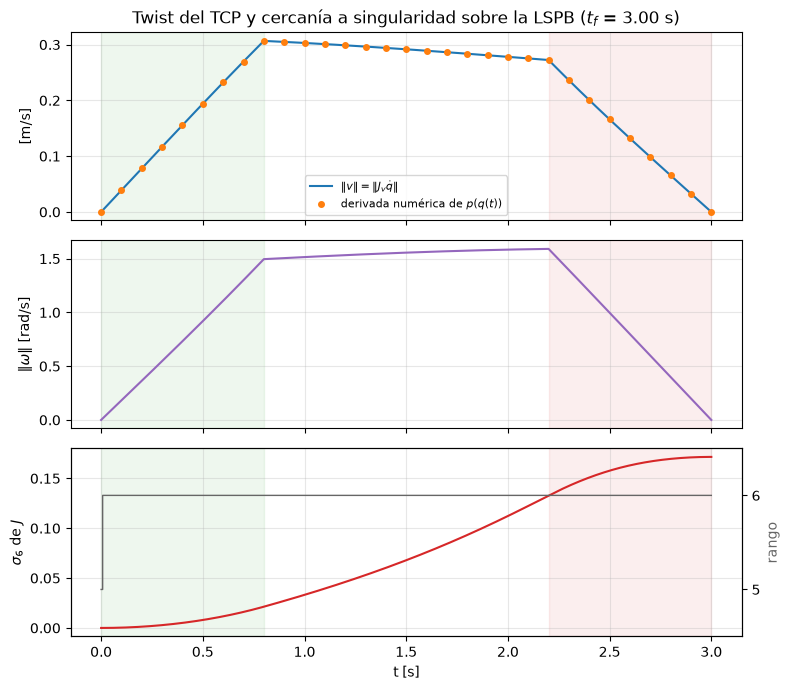

In [129]:
# Entrada: el muestreo de la etapa 5 (t_tr, q_tr, qd_tr); no se vuelve a muestrear.
twist = np.array([jb.jacobiano(qk) @ qdk for qk, qdk in zip(q_tr, qd_tr)])
p_t = np.array([m.fk(qk)[:3, 3] for qk in q_tr])
H = 1e-6
v_num = np.array([(m.fk(TR.evaluar(tk + H)[0])[:3, 3] - m.fk(TR.evaluar(tk - H)[0])[:3, 3]) / (2 * H) for tk in t_tr])
rangos = np.array([jb.analisis_rango(jb.jacobiano(qk), tol=TOL_RANGO)["rango"] for qk in q_tr])
sig6 = np.array([jb.analisis_rango(jb.jacobiano(qk), tol=TOL_RANGO)["sigma"][-1] for qk in q_tr])

err_v = np.abs(twist[:, :3] - v_num)[1:-1].max()
verificar(f"v = J q̇ coincide con la derivada numérica de p(q(t)) (dif. máx {err_v:.1e} m/s)", err_v < 1e-6)
i_reg = np.argmax(rangos == 6)
print(f"\n|v| máx = {np.linalg.norm(twist[:, :3], axis=1).max():.3f} m/s,  |w| máx = {np.linalg.norm(twist[:, 3:], axis=1).max():.3f} rad/s")
print(f"rango de J: {rangos[0]} en t = 0 (q_i, muñeca singular); 6 desde t = {t_tr[i_reg]:.4f} s hasta t_f")
print(f"Ïƒ6 crece a medida que q5 se aleja de 0: Ïƒ6(t_c) = {sig6[np.argmin(abs(t_tr - TR.tc))]:.4f},  Ïƒ6(t_f / 2) = {sig6[len(t_tr) // 2]:.4f},  Ïƒ6(t_f) = {sig6[-1]:.4f}")

fig, axs = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
axs[0].plot(t_tr, np.linalg.norm(twist[:, :3], axis=1), label=r"$\|v\| = \|J_v\dot q\|$")
axs[0].plot(t_tr[::40], np.linalg.norm(v_num, axis=1)[::40], "o", ms=4, label="derivada numérica de $p(q(t))$")
axs[0].set_ylabel("[m/s]"); axs[0].legend(fontsize=8)
axs[1].plot(t_tr, np.linalg.norm(twist[:, 3:], axis=1), color="tab:purple")
axs[1].set_ylabel(r"$\|\omega\|$ [rad/s]")
axs[2].plot(t_tr, sig6, color="tab:red"); axs[2].set_ylabel(r"$\sigma_6$ de $J$")
ax2 = axs[2].twinx(); ax2.step(t_tr, rangos, color="0.4", where="post", linewidth=1); ax2.set_ylabel("rango", color="0.4")
ax2.set_ylim(4.5, 6.5); ax2.set_yticks([5, 6])
for ax in axs:
    ax.axvspan(0, TR.tc, color="tab:green", alpha=0.08); ax.axvspan(TR.tf - TR.tc, TR.tf, color="tab:red", alpha=0.08)
    ax.grid(alpha=0.3)
axs[0].set_title(f"Twist del TCP y cercanía a singularidad sobre la LSPB ($t_f$ = {TR.tf:.2f} s)")
axs[2].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(FIG / "P6_jacobiano_trayectoria.png", dpi=150); fig.savefig(FIG / "P6_jacobiano_trayectoria.pdf")
plt.show()

**Lectura.** El robot **arranca en una singularidad de muñeca** ($q_i = 0$ tiene $q_5 = 0$): en $t = 0$ el rango es 5.
Apenas $q_5$ se mueve, $\sigma_6$ crece y el rango vuelve a 6. Eso no causa ningún problema porque la trayectoria es
**articular**: nunca se invierte $J$, solo se multiplica $J\dot q$, y además el robot está en reposo ($\dot q = 0$).
Distinto sería pedir una trayectoria **cartesiana** que pase por ahí (sección 6.6).

### 6.5 Singularidades del IRB 120: criterio de rango

$q^*$ es singular si $\operatorname{rank} J(q^*) < \operatorname{rank}_{\max} = \min(6, 6) = 6$ (*W08-S02, diapositiva 10*;
*Referencia visual de singularidades W08, criterio A*): el rango cuenta las direcciones instantáneas independientes en
que el TCP puede moverse, así que existe al menos un twist $[v;\omega]$ que **no puede generar** con ningún $\dot q$.
El rango numérico se mide con la descomposición en valores singulares (Siciliano et al., 2009, sec. 3.9; es lo que
hace `np.linalg.matrix_rank` del *ejemplo Python de rango, W08-S02*):

$$
J = U\Sigma V^T = \sum_{i=1}^{6}\sigma_i u_i v_i^T,\qquad \sigma_1\ge\dots\ge\sigma_6\ge 0,\qquad
\text{rango numérico} = \#\{\sigma_i > 10^{-6}\}
$$

Si $\sigma_6 = 0$, $u_6$ es la **dirección cartesiana perdida** y $v_6$ un **movimiento articular nulo** (mueve las
juntas sin mover el TCP), porque $Jv_6 = \sigma_6 u_6$.

**El determinante solo como complemento.** $\det J = 0$ prueba singularidad solo porque $J$ es cuadrada (6×6); la
definición universal es la pérdida de rango (*W08-S02, diapositiva 11*; *Referencia visual W08, criterio B*).
$\det J = \prod\sigma_i$ no dice cuántas
ni cuáles direcciones se pierden y su valor depende de las unidades (mezcla m y rad). Sirve para **ubicar** las
singularidades: con el punto de referencia en el centro de muñeca W, las juntas 4 a 6 no mueven W y $J$ queda
triangular por bloques (desacople de singularidades, Siciliano, sec. 3.3.1):

$$
J_W = \begin{bmatrix} J_{11} & 0 \\ J_{21} & J_{22}\end{bmatrix} \;\Rightarrow\;
\det J = \underbrace{L_2 L_3\cos(q_3-\delta)\,r_W}_{\det J_{11}\ \text{(brazo)}}\cdot\underbrace{(-\sin q_5)}_{\det J_{22}\ \text{(muñeca)}}
$$

con $L_2 = 0.270$ m, $L_3 = 0.310$ m, $\delta = 13.05°$ (los de Pieper) y $r_W$ la distancia horizontal con signo de W
al eje 1. Cambiar el punto de referencia del TCP a W no cambia el determinante (Siciliano, sec. 3.3.1).

In [130]:
razon = [np.linalg.det(jb.jacobiano(q)) / np.prod(jb.det_factorizado(q)) for q in muestras[1:]]
verificar(f"det J = L2 L3 cos(q3-δ) r_W · (-sin q5) en 200 posturas (razón entre {min(razon):.6f} y {max(razon):.6f})",
          np.allclose(razon, 1.0, atol=1e-9))
verificar("con referencia en W, las juntas 4-6 no mueven W (bloque J_v,4..6 = 0)",
          all(np.abs(jb.jacobiano(q, "muneca")[:3, 3:]).max() < 1e-12 for q in muestras))

def q2_hombro(q3):
    # bisección de r_W(q2) = 0 con q1 = 0, q3 dado: W sobre el eje 1
    f = lambda q2: jb.radio_muneca(np.array([0, q2, q3, 0, 0.5, 0]))
    a, b = -np.pi / 2, 0.0
    for _ in range(80):
        c = (a + b) / 2
        a, b = (c, b) if np.sign(f(c)) == np.sign(f(a)) else (a, c)
    return (a + b) / 2

Q3_CODO = pp.DELTA - np.pi / 2
casos = {
    "muñeca (q5 = 0)": np.deg2rad([20, 10, 30, 40, 0, 60]),
    "codo estirado (q3 = δ − 90°)": np.array([0.3, 0.2, Q3_CODO, 0.4, 0.5, 0.6]),
    "hombro (r_W = 0)": np.array([0.0, q2_hombro(0.3), 0.3, 0.4, 0.5, 0.6]),
    "regular (q_f)": Q_F,
}
print(f"\n{'caso':<30} {'q [rad]':<62} {'σ6':>10} {'rango':>6} {'en límites':>11}")
for nombre_c, qc in casos.items():
    r = jb.analisis_rango(jb.jacobiano(qc), tol=TOL_RANGO)
    print(f"{nombre_c:<30} {str(np.round(qc, 4)):<62} {r['sigma'][-1]:10.2e} {r['rango']:>6} {'sí' if m.dentro_de_limites(qc) else 'no':>11}")
    verificar(f"{nombre_c}: rango {'5' if 'regular' not in nombre_c else '6'}",
              r["rango"] == (6 if "regular" in nombre_c else 5))

✔ det J = L2 L3 cos(q3-δ) r_W · (-sin q5) en 200 posturas (razón entre 1.000000 y 1.000000)
✔ con referencia en W, las juntas 4-6 no mueven W (bloque J_v,4..6 = 0)

caso                           q [rad]                                                                σ6  rango  en límites
muñeca (q5 = 0)                [0.3491 0.1745 0.5236 0.6981 0.     1.0472]                      3.41e-17      5          sí
✔ muñeca (q5 = 0): rango 5
codo estirado (q3 = δ − 90°)   [ 0.3    0.2   -1.343  0.4    0.5    0.6  ]                      1.01e-16      5          sí
✔ codo estirado (q3 = δ − 90°): rango 5
hombro (r_W = 0)               [ 0.     -0.8955  0.3     0.4     0.5     0.6   ]                3.43e-17      5          sí
✔ hombro (r_W = 0): rango 5
regular (q_f)                  [-0.3805  0.168   0.8225  0.      0.5802  2.7611]                1.72e-01      6          sí
✔ regular (q_f): rango 6


| Singularidad | Condición | Qué pasa físicamente | ¿Alcanzable? |
|---|---|---|---|
| **Muñeca** | $q_5 = 0$ | Ejes 4 y 6 **colineales**: dos motores producen el mismo giro | Sí; incluye $q_i = 0$ |
| **Codo** | $q_3 = \delta - 90° = -76.95°$ | Brazo **totalmente estirado**: borde exterior del espacio de trabajo | Sí ($q_3 \ge -110°$) |
| **Hombro** | $r_W = 0$ | W sobre el eje 1: girar la base no traslada W | Sí |

La otra raíz del codo, $q_3 = \delta + 90° = 103°$ (brazo plegado), queda fuera del límite $q_3 \le 70°$.

### 6.6 Experimento: aproximación a la singularidad de muñeca

Experimento independiente de la fórmula del determinante. Se parte de $q_f$ y se fijan $q_1, q_2, q_3, q_4, q_6$; solo
$q_5$ se acerca a cero:

$$
q_5 \in \{30°,\ 10°,\ 3°,\ 1°,\ 0.3°,\ 0.1°,\ 0.01°,\ 0°\}
$$

Es la "secuencia de poses hacia una singularidad conocida" que pide la guía (*sec. 3.3*). En cada punto se
registran los valores singulares, el rango numérico, la condición $\kappa = \sigma_1/\sigma_6$, el determinante
(complemento) y la velocidad articular necesaria para producir un twist unitario en la dirección más débil con la IK
diferencial $\dot q = J^{-1}\dot x_d$ (*W08-S01, diapositiva 11*): $\dot q = J^{-1}u_6 = v_6/\sigma_6$, es decir
$\lVert\dot q\rVert = 1/\sigma_6$. Es la versión 6×6 del ejemplo $J_\varepsilon = \operatorname{diag}(1,\varepsilon)$,
$\dot q = 1/\varepsilon$ (*W08-S02, diapositiva 13*), con $\varepsilon = \sigma_6$.

 q5 [rad]         σ6  rango          κ       det J  σ6/|sin q5|  |q̇| = 1/σ6 [rad/s]
   0.5236   1.60e-01      6   1.14e+01   -9.33e-03       0.3192                  6.3
   0.1745   5.37e-02      6   3.43e+01   -3.24e-03       0.3092                 18.6
   0.0524   1.52e-02      6   1.21e+02   -9.77e-04       0.2913                 65.6
   0.0175   4.99e-03      6   3.71e+02   -3.26e-04       0.2856                200.6
   0.0052   1.49e-03      6   1.25e+03   -9.77e-05       0.2836                673.4
   0.0017   4.94e-04      6   3.75e+03   -3.26e-05       0.2830               2024.3
   0.0002   4.94e-05      6   3.75e+04   -3.26e-06       0.2828              20261.1
   0.0000   1.14e-17      5   1.62e+17   -3.43e-18          nan                  inf
✔ rango 6 para q5 ≠ 0 y rango 5 exactamente en q5 = 0
✔ σ6 ∝ |sin q5| cerca de la singularidad (σ6/|sin q5| entre 0.2828 y 0.2836 para q5 ≤ 0.0052 rad)


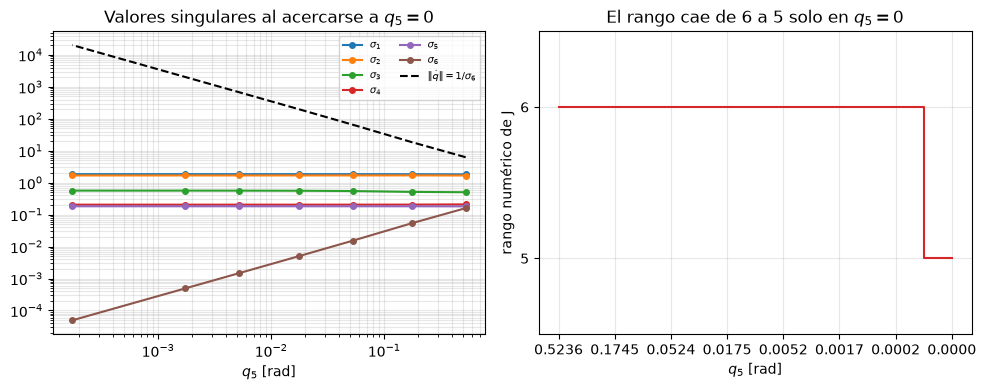

In [131]:
Q5_DEG = [30, 10, 3, 1, 0.3, 0.1, 0.01, 0]
filas6 = []
print(f"{'q5 [rad]':>9} {'σ6':>10} {'rango':>6} {'κ':>10} {'det J':>11} {'σ6/|sin q5|':>12} {'|q̇| = 1/σ6 [rad/s]':>20}")
for q5 in Q5_DEG:
    qe = Q_F.copy(); qe[4] = np.deg2rad(q5)
    r = jb.analisis_rango(jb.jacobiano(qe), tol=TOL_RANGO)
    filas6.append((q5, r))
    s6 = r["sigma"][-1]
    print(f"{np.deg2rad(q5):9.4f} {s6:10.2e} {r['rango']:6d} {r['kappa']:10.2e} {r['det']:11.2e} "
          f"{(s6 / abs(np.sin(qe[4])) if q5 else float('nan')):12.4f} {(1 / s6 if s6 > 1e-12 else float('inf')):20.1f}")

verificar("rango 6 para q5 ≠ 0 y rango 5 exactamente en q5 = 0",
          all(r["rango"] == 6 for q5, r in filas6[:-1]) and filas6[-1][1]["rango"] == 5)
cocientes = [r["sigma"][-1] / abs(np.sin(np.deg2rad(q5))) for q5, r in filas6[:-1] if q5 <= 0.3]
verificar(f"σ6 ∝ |sin q5| cerca de la singularidad (σ6/|sin q5| entre {min(cocientes):.4f} y {max(cocientes):.4f} para q5 ≤ 0.0052 rad)",
          max(cocientes) / min(cocientes) < 1.01)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
q5_pos = np.deg2rad([q5 for q5, _ in filas6[:-1]])
S = np.array([r["sigma"] for _, r in filas6[:-1]])
for i in range(6):
    axs[0].loglog(q5_pos, S[:, i], "o-", ms=4, label=fr"$\sigma_{i+1}$")
axs[0].loglog(q5_pos, 1 / S[:, -1], "k--", label=r"$\|\dot q\| = 1/\sigma_6$")
axs[0].set_xlabel("$q_5$ [rad]"); axs[0].set_title("Valores singulares al acercarse a $q_5 = 0$"); axs[0].legend(fontsize=7, ncol=2)
axs[0].grid(alpha=0.3, which="both")
xs = np.arange(len(filas6))
axs[1].step(xs, [r["rango"] for _, r in filas6], where="mid", color="tab:red")
axs[1].set_xticks(xs, [f"{np.deg2rad(q5):.4f}" for q5, _ in filas6]); axs[1].set_yticks([5, 6]); axs[1].set_ylim(4.5, 6.5)
axs[1].set_xlabel("$q_5$ [rad]"); axs[1].set_ylabel("rango numérico de J"); axs[1].set_title("El rango cae de 6 a 5 solo en $q_5 = 0$")
axs[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "P6_experimento_singularidad.png", dpi=150); fig.savefig(FIG / "P6_experimento_singularidad.pdf")
plt.show()

### 6.7 Qué movilidad se pierde y qué NO significa

**Movimiento nulo.** En $q_5 = 0$ los ejes $z_3$ y $z_5$ coinciden, así que las juntas 4 y 6 giran alrededor del mismo
eje. El vector $v_6$ de la SVD es $\propto(0,0,0,1,0,-1)$: $\dot q_4 = -\dot q_6$ hace girar los dos motores en sentidos
opuestos y el TCP queda quieto.

**Dirección perdida.** La muñeca solo puede aportar velocidad angular en el plano de $z_3$ y $z_4$: se pierde la
rotación alrededor de $z_3\times z_4$. Con W como punto de referencia, la parte angular de $u_6$ es paralela a ese eje.

**Amplificación de velocidad, no torque infinito.** Cerca de la singularidad, producir un twist en la dirección $u_6$
exige $\lVert\dot q\rVert = 1/\sigma_6 \propto 1/|\sin q_5|$ (tabla de 6.6): velocidades articulares "inusualmente altas
y peligrosas" para una velocidad cartesiana finita (*Referencia visual W08, punto 4*). Pero la singularidad es **cinemática**: en
estática $\tau = J^T F$ (dualidad cinetoestática, Siciliano, sec. 3.8), y $J^T u_6 = \sigma_6 v_6 \to 0$. Una fuerza en
la dirección perdida **no pide torque**: la estructura la soporta. Los torques solo crecen si se **insiste** en seguir
una trayectoria **cartesiana** a través de la singularidad, porque $\ddot q = J^{-1}(\ddot x - \dot J\dot q)$ crece con
$1/\sigma_6$. La LSPB de este trabajo es articular y no invierte $J$.

In [132]:
q_sing = Q_F.copy(); q_sing[4] = 0.0
r_s = jb.analisis_rango(jb.jacobiano(q_sing), tol=TOL_RANGO)
v6 = r_s["v_debil"] * np.sign(r_s["v_debil"][3])
print("v6 (movimiento articular nulo) =", np.round(v6, 4))
verificar("movimiento nulo en q5 = 0: v6 ∝ (0,0,0,1,0,-1), es decir q̇4 = −q̇6",
          np.allclose(np.abs(v6), np.array([0, 0, 0, 1, 0, 1]) / np.sqrt(2), atol=1e-9) and v6[5] < 0)
verificar(f"el TCP no se mueve con ese movimiento: |J v6| = {np.linalg.norm(jb.jacobiano(q_sing) @ v6):.1e}",
          np.linalg.norm(jb.jacobiano(q_sing) @ v6) < 1e-9)

T_s = m.marcos(q_sing)
eje_perdido = np.cross(T_s[3][:3, 2], T_s[4][:3, 2])
u6_W = jb.analisis_rango(jb.jacobiano(q_sing, "muneca"), tol=TOL_RANGO)["u_debil"]
cos_ang = abs(u6_W[3:] @ eje_perdido) / (np.linalg.norm(u6_W[3:]) * np.linalg.norm(eje_perdido))
verificar(f"dirección perdida (referencia W): parte angular de u6 paralela a z3 × z4 (|cos| = {cos_ang:.6f})", cos_ang > 1 - 1e-9)
verificar(f"J^T u6 = σ6 v6 ≈ 0: una fuerza en la dirección perdida no pide torque (|J^T u6| = {np.linalg.norm(jb.jacobiano(q_sing).T @ r_s['u_debil']):.1e})",
          np.linalg.norm(jb.jacobiano(q_sing).T @ r_s["u_debil"]) < 1e-9)
v45 = VMAX[4]
for q5, r in filas6:
    if 0 < q5 <= 1:
        print(f"q5 = {np.deg2rad(q5):.4f} rad: twist unitario en u6 pide |q̇| = {1 / r['sigma'][-1]:9.1f} rad/s  (vmax usado de q5: {v45:.2f} rad/s)")

v6 (movimiento articular nulo) = [-0.     -0.      0.      0.7071 -0.     -0.7071]
✔ movimiento nulo en q5 = 0: v6 ∝ (0,0,0,1,0,-1), es decir q̇4 = −q̇6
✔ el TCP no se mueve con ese movimiento: |J v6| = 2.5e-16
✔ dirección perdida (referencia W): parte angular de u6 paralela a z3 × z4 (|cos| = 1.000000)
✔ J^T u6 = σ6 v6 ≈ 0: una fuerza en la dirección perdida no pide torque (|J^T u6| = 1.9e-16)
q5 = 0.0175 rad: twist unitario en u6 pide |q̇| =     200.6 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 = 0.0052 rad: twist unitario en u6 pide |q̇| =     673.4 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 = 0.0017 rad: twist unitario en u6 pide |q̇| =    2024.3 rad/s  (vmax usado de q5: 1.40 rad/s)
q5 = 0.0002 rad: twist unitario en u6 pide |q̇| =   20261.1 rad/s  (vmax usado de q5: 1.40 rad/s)


In [133]:
cerrar_etapa("Jacobiano y singularidades", J_f=J_f, twist=twist, rangos=rangos)

■ Etapa 6 (Jacobiano y singularidades) cerrada: 15/15 verificaciones aprobadas
  entrega a la siguiente etapa: J_f, twist, rangos


## 7. Dinámica reducida 1R sobre la trayectoria LSPB

> **Etapa 7.** **Entra:** el muestreo `t_tr, q_tr, qd_tr, qdd_tr` (etapa 5), `rangos` (etapa 6) y `DIN` · **Sale:** `tau_I`, `tau_g`, `tau` a lo largo de la trayectoria


La cinemática dice **cómo** se mueve el robot; la dinámica dice **cuánto esfuerzo** cuesta: $(q,\dot q,\ddot q)\to\tau$
(*W09-S02, diapositiva 2*). Para un robot de $n$ GDL la ecuación general es (*W09-S02, diapositiva 6*)

$$
\tau = M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q)
$$

con $M\ddot q$ el término **inercial**, $C\dot q$ los efectos de **Coriolis y centrífugos** (acoplamiento entre juntas) y
$g(q)$ la **gravedad**. La guía pide el **modelo reducido 1R estudiado en clase**, $\tau = J\ddot q + mg\ell_c\sin q$,
evaluado con la trayectoria LSPB, graficar $\tau(t)$ e interpretar las regiones de mayor esfuerzo y la diferencia
entre degradación cinemática (singularidad) y comportamiento dinámico (*Guía oficial Hito 2, sec. 3.4*). El handoff de
dinámica indica **no derivar los 6 GDL del IRB 120** sin datos inerciales del fabricante (*W09-S01, handoff, punto 0*).

Rúbrica E (15 %), nivel alto: usa el modelo 1R trabajado; documenta supuestos y parámetros; calcula $\tau$ a partir de
$q,\dot q,\ddot q$; separa e interpreta contribuciones; presenta $\tau(t)$ y lo relaciona con la trayectoria.

### 7.1 Derivación por Euler-Lagrange (péndulo rígido 1R)

Eslabón rígido que gira en un plano vertical; $q$ se mide **desde la vertical hacia abajo**, $m$ es la masa, $\ell_c$ la
distancia de la junta al centro de masa e $I_c$ la inercia respecto al centro de masa (*W09-S02, diapositivas 3 a 5*):

1. **Inercia en la junta** (Steiner): $J = I_c + m\ell_c^2$.
2. **Energías:** $T = \tfrac12 J\dot q^2$, $\quad V = mg\ell_c(1-\cos q)$.
3. **Lagrangiano:** $L = T - V = \tfrac12 J\dot q^2 - mg\ell_c(1-\cos q)$.
4. **Derivadas:** $\dfrac{\partial L}{\partial\dot q} = J\dot q \Rightarrow \dfrac{d}{dt}\dfrac{\partial L}{\partial\dot q} = J\ddot q$, $\quad \dfrac{\partial L}{\partial q} = -mg\ell_c\sin q$.
5. **Euler-Lagrange:** $\dfrac{d}{dt}\dfrac{\partial L}{\partial\dot q} - \dfrac{\partial L}{\partial q} = \tau$:

$$
\boxed{\tau = \underbrace{J\ddot q}_{\tau_I\ \text{inercial}} + \underbrace{mg\ell_c\sin q}_{\tau_g\ \text{gravedad}}}
$$

En 1R no hay término de Coriolis ($C = 0$): es el único caso sin acoplamiento entre juntas (*W09-S02, diapositiva 6;
solucionario W09-S02*). Código: `dinamica.py`, función `tau_1r`.

### 7.2 Validación con los casos de clase

Antes de usarlo en el robot, el código reproduce los resultados de clase:

- **Estática** (*W09-S02, diapositiva 5*): con $\dot q = \ddot q = 0$, $\tau(0) = 0$ y $\tau(\pi/2) = mg\ell_c$.
- **Hoja de trabajo W09-S02, ejercicio 3** ($m = 2$ kg, $\ell_c = 0.4$ m): $\tau = 7.848\sin q$; en $\pi/6$ da 3.924 N·m.
- **Ejercicio 4** ($J = 0.4$ kg·m², $\ddot q = 3$ rad/s²): $\tau_I = 1.2$ N·m.
- **Tabla de la diapositiva 8** (1R ilustrativo $J = 0.25$, $m = 1$, $\ell_c = 0.5$; LSPB de clase $0\to2$ rad,
  $t_f = 3$ s, $\ddot q_c = 1$): 0.86, 4.13 y 4.43 N·m en $t = 0.5$, 1.5 y 2.5 s.

In [134]:
requiere("Trayectoria LSPB", "Jacobiano y singularidades")
verificar("estática: τ(0) = 0 y τ(π/2) = m g lc", np.isclose(dyn.tau_1r(0.0, 0.0)[2], 0.0)
          and np.isclose(dyn.tau_1r(np.pi / 2, 0.0)[2], dyn.M_KG * dyn.G * dyn.LC_M))
verificar("W09-S02 ej. 3: τ(π/6) = 3.924 N·m con m = 2 kg, lc = 0.4 m",
          np.isclose(dyn.tau_1r(np.pi / 6, 0.0, m=2.0, lc=0.4)[2], 3.924, atol=5e-4))
verificar("W09-S02 ej. 4: τ_I = 1.2 N·m con J = 0.4 kg·m², q̈ = 3 rad/s²", np.isclose(dyn.tau_1r(0.0, 3.0, J=0.4)[0], 1.2))

def lspb_clase(tk, qi=0.0, qf=2.0, tf=3.0, a=1.0, tc=1.0):
    # perfil de la clase W09-S01/S02 (qi = 0 -> qf = 2 rad, tf = 3 s, q̈c = 1 rad/s², tc = 1 s)
    if tk <= tc:
        return qi + 0.5 * a * tk**2, a
    if tk <= tf - tc:
        return qi + a * tc * (tk - tc / 2), 0.0
    return qf - 0.5 * a * (tf - tk)**2, -a

tabla_clase = {0.5: 0.86, 1.5: 4.13, 2.5: 4.43}
for tk, esperado in tabla_clase.items():
    qk, qddk = lspb_clase(tk)
    tau_k = dyn.tau_1r(qk, qddk, J=0.25, m=1.0, lc=0.5)[2]
    verificar(f"W09-S02 diap. 8: t = {tk} s -> τ = {tau_k:.2f} N·m (clase: {esperado})", round(tau_k, 2) == esperado)

✔ estática: τ(0) = 0 y τ(π/2) = m g lc
✔ W09-S02 ej. 3: τ(π/6) = 3.924 N·m con m = 2 kg, lc = 0.4 m
✔ W09-S02 ej. 4: τ_I = 1.2 N·m con J = 0.4 kg·m², q̈ = 3 rad/s²
✔ W09-S02 diap. 8: t = 0.5 s -> τ = 0.86 N·m (clase: 0.86)
✔ W09-S02 diap. 8: t = 1.5 s -> τ = 4.13 N·m (clase: 4.13)
✔ W09-S02 diap. 8: t = 2.5 s -> τ = 4.43 N·m (clase: 4.43)


### 7.3 Aplicación al IRB 120: qué junta, qué parámetros y qué supuestos

**Junta elegida: la 3 (codo), moviendo el antebrazo** (codo → centro de muñeca W). Es la que tiene la **gravedad más
cambiante** en esta trayectoria: en $q_i$ el antebrazo está casi horizontal (brazo de palanca máximo) y durante el
movimiento baja hasta unos 46° de la vertical, **cruzando la horizontal**. El hombro (junta 2) apenas se mueve 9.6°
y la muñeca tiene palancas pequeñas.

**Ángulo del 1R.** Los ejes 2 y 3 son paralelos y horizontales, así que la orientación del antebrazo respecto a la
vertical es la suma $q_2 + q_3$ más una constante geométrica. Medido desde la vertical hacia abajo, positivo en el
sentido de $q_3$ (en $q = 0$ el antebrazo apunta a W, 13.05° sobre la horizontal):

$$
\theta = q_2 + q_3 - \delta - \frac{\pi}{2},\qquad \dot\theta = \dot q_2 + \dot q_3,\qquad \ddot\theta = \ddot q_2 + \ddot q_3
$$

| Parámetro | Valor | Procedencia |
|---|---|---|
| Longitud del antebrazo $L$ | 0.310 m | $\sqrt{a_3^2 + d_4^2}$, tabla DH (Bahani et al., 2023) = $L_3$ de Pieper |
| Centro de masa $\ell_c$ | $L/2$ = 0.155 m | **Supuesto:** barra uniforme |
| Masa $m$ | 1 kg | **Ilustrativa**, la del modelo 1R de clase (*W09-S02, código torque_python*). ABB no publica masas por eslabón |
| $I_c$ | $mL^2/12$ | Barra uniforme respecto a su centro |
| $J$ | $I_c + m\ell_c^2 = mL^2/3$ = 0.0320 kg·m² | Steiner (*W09-S02, diapositiva 4*) |
| $g$ | 9.81 m/s² | |

**Supuestos declarados.** (1) Eje del codo fijo: se desprecia que el hombro lo traslada y el acoplamiento de
Coriolis/centrífugo con las otras juntas (en el robot real $C \ne 0$). (2) Solo el antebrazo: la muñeca, la
herramienta y la carga no se incluyen. (3) Sin fricción ni inercia del rotor. (4) **$\tau$ es lineal en $m$** (también
$J \propto m$): para otra masa basta multiplicar; las formas de las curvas y las conclusiones no cambian.

**Validación del 1R con la geometría 3D.** El término de gravedad del 1R debe ser igual al momento del peso del
antebrazo respecto al eje del codo $z_2$, calculado con la FK completa: $\tau_g = z_2\cdot\big((p_c - o_2)\times(0,0,mg)\big)$.

In [135]:
# ---- Entradas de la etapa 7 (dinámica 1R del codo)
M_KG = 1.0                 # kg: masa ilustrativa de clase (ABB no publica masas por eslabón)
FRACCION_LC = 0.5          # adimensional: ℓc = FRACCION_LC · L; 0.5 = barra uniforme
G = 9.81                   # m/s²
N_ENERGIA = 40001          # rejilla fina solo para la integral de energía
L_1R = pp.L3               # m: codo -> centro de muñeca (tabla DH)
LC_1R = FRACCION_LC * L_1R
DIN = {"J": M_KG * L_1R**2 / 12 + M_KG * LC_1R**2,      # Ic de barra uniforme + Steiner
       "m": M_KG, "lc": LC_1R, "g": G}
print(f"Entradas de la etapa 7: m = {M_KG} kg, L = {L_1R:.4f} m, ℓc = {LC_1R:.4f} m, J = {DIN['J']:.5f} kg·m², g = {G} m/s²")

Entradas de la etapa 7: m = 1.0 kg, L = 0.3100 m, ℓc = 0.1550 m, J = 0.03203 kg·m², g = 9.81 m/s²


In [136]:
print(f"L = {L_1R:.4f} m,  lc = {DIN['lc']:.4f} m,  m = {DIN['m']} kg,  J = {DIN['J']:.5f} kg·m²")
# Entrada: el muestreo de la etapa 5; Î¸, Î¸Ì‡, Î¸Ìˆ del antebrazo salen de q2 + q3.
th = dyn.angulo_antebrazo(q_tr)
thd = qd_tr[:, 1] + qd_tr[:, 2]
thdd = qdd_tr[:, 1] + qdd_tr[:, 2]
tau_I, tau_g, tau = dyn.tau_1r(th, thdd, **DIN)
err_g = max(abs(dyn.tau_gravedad_exacta(qk, m=DIN["m"], lc=DIN["lc"], g=DIN["g"]) - tg) for qk, tg in zip(q_tr, tau_g))
verificar(f"τ_g del 1R = momento del peso respecto al eje del codo con la FK 3D (dif. máx {err_g:.1e} N·m)", err_g < 1e-9)
print(f"θ: {th[0]:.4f} rad en q_i -> {th[-1]:.4f} rad en q_f   (θ = ±π/2 rad: antebrazo horizontal)")

L = 0.3100 m,  lc = 0.1550 m,  m = 1.0 kg,  J = 0.03203 kg·m²
✔ τ_g del 1R = momento del peso respecto al eje del codo con la FK 3D (dif. máx 6.7e-16 N·m)
θ: -1.7986 rad en q_i -> -0.8080 rad en q_f   (θ = ±π/2 rad: antebrazo horizontal)


### 7.4 $\tau(t)$ sobre la LSPB y sus contribuciones

Se inyectan $q(t),\dot q(t),\ddot q(t)$ de la LSPB de la sección 5 (*W09-S02, diapositiva 7*). Las gráficas están
alineadas en el tiempo con las fases de la LSPB (*matriz diagnóstica W10-S01*).

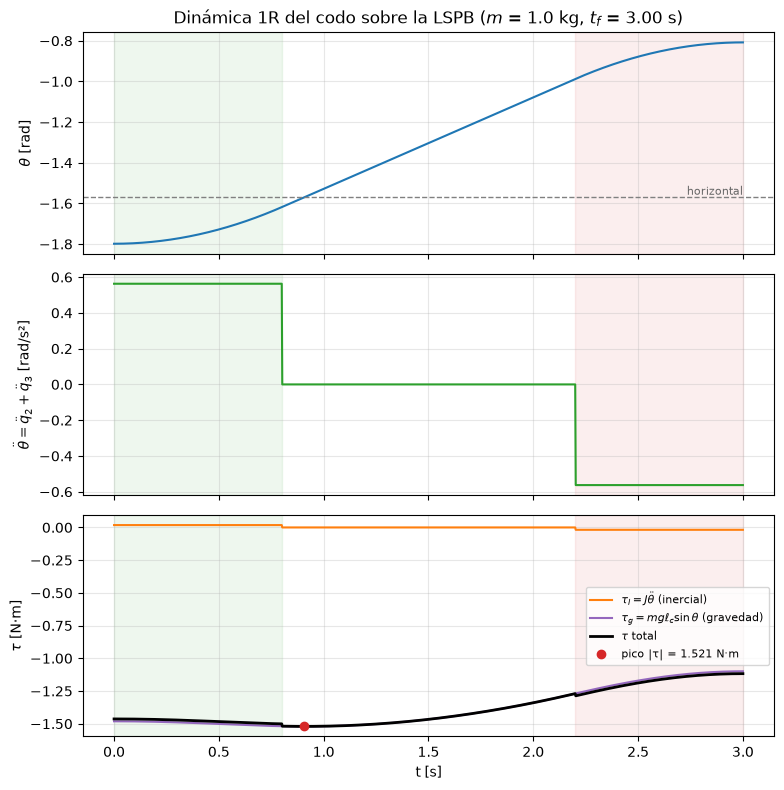

fase              t [s]   θ [rad]  θ̈ [rad/s²]  τ_I [N·m]  τ_g [N·m]   τ [N·m]
aceleración       0.400   -1.7535        0.563     0.0180    -1.4953   -1.4772
vel. constante    1.500   -1.3033        0.000     0.0000    -1.4665   -1.4665
desaceleración    2.600   -0.8530       -0.563    -0.0180    -1.1454   -1.1634

pico |τ| = 1.5206 N·m en t = 0.905 s (vel. constante), θ = -1.5712 rad
|τ_I| máx = 0.0180 N·m  vs  |τ_g| máx = 1.5206 N·m
✔ en velocidad constante θ̈ = 0, pero τ ≠ 0 (la gravedad sigue actuando)
✔ τ_I es un reflejo de θ̈: escalones en t_c y t_f − t_c


In [137]:
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
axs[0].plot(t_tr, th, color="tab:blue")
axs[0].axhline(-np.pi / 2, color="0.5", linestyle="--", linewidth=1)
axs[0].text(t_tr[-1], -np.pi / 2, " horizontal", va="bottom", ha="right", fontsize=8, color="0.4")
axs[0].set_ylabel(r"$\theta$ [rad]")
axs[1].plot(t_tr, thdd, color="tab:green"); axs[1].set_ylabel(r"$\ddot\theta = \ddot q_2 + \ddot q_3$ [rad/s²]")
axs[2].plot(t_tr, tau_I, label=r"$\tau_I = J\ddot\theta$ (inercial)", color="tab:orange")
axs[2].plot(t_tr, tau_g, label=r"$\tau_g = mg\ell_c\sin\theta$ (gravedad)", color="tab:purple")
axs[2].plot(t_tr, tau, label=r"$\tau$ total", color="k", linewidth=2)
k_pico = np.argmax(np.abs(tau))
axs[2].plot(t_tr[k_pico], tau[k_pico], "o", color="tab:red", label=f"pico |τ| = {abs(tau[k_pico]):.3f} N·m")
axs[2].set_ylabel(r"$\tau$ [N·m]"); axs[2].legend(fontsize=8, loc="center right")
for ax in axs:
    ax.axvspan(0, TR.tc, color="tab:green", alpha=0.08); ax.axvspan(TR.tf - TR.tc, TR.tf, color="tab:red", alpha=0.08)
    ax.grid(alpha=0.3)
axs[0].set_title(f"Dinámica 1R del codo sobre la LSPB ($m$ = {DIN['m']} kg, $t_f$ = {TR.tf:.2f} s)")
axs[2].set_xlabel("t [s]")
fig.tight_layout(); fig.savefig(FIG / "P7_torque_1R.png", dpi=150); fig.savefig(FIG / "P7_torque_1R.pdf")
plt.show()

print(f"{'fase':<16} {'t [s]':>6} {'θ [rad]':>9} {'θ̈ [rad/s²]':>12} {'τ_I [N·m]':>10} {'τ_g [N·m]':>10} {'τ [N·m]':>9}")
for fase, tk in (("aceleración", TR.tc / 2), ("vel. constante", TR.tf / 2), ("desaceleración", TR.tf - TR.tc / 2)):
    i = np.argmin(np.abs(t_tr - tk))
    print(f"{fase:<16} {t_tr[i]:6.3f} {th[i]:9.4f} {thdd[i]:12.3f} {tau_I[i]:10.4f} {tau_g[i]:10.4f} {tau[i]:9.4f}")
print(f"\npico |τ| = {abs(tau[k_pico]):.4f} N·m en t = {t_tr[k_pico]:.3f} s ({TR.fase(t_tr[k_pico])}), θ = {th[k_pico]:.4f} rad")
print(f"|τ_I| máx = {np.abs(tau_I).max():.4f} N·m  vs  |τ_g| máx = {np.abs(tau_g).max():.4f} N·m")
crucero = (t_tr > TR.tc) & (t_tr < TR.tf - TR.tc)
verificar("en velocidad constante θ̈ = 0, pero τ ≠ 0 (la gravedad sigue actuando)",
          np.allclose(tau_I[crucero], 0) and np.abs(tau[crucero]).min() > 0.5)
verificar("τ_I es un reflejo de θ̈: escalones en t_c y t_f − t_c", np.allclose(tau_I, DIN["J"] * thdd))

**Lectura (relación con la trayectoria).**

- **$\tau_I$ copia el perfil de $\ddot\theta$**: escalón positivo en la aceleración, cero en velocidad constante y escalón
  negativo en la desaceleración (*W09-S02, código torque_python, interpretación obligatoria*).
- **$\tau_g$ evoluciona suave, como $\sin\theta$**: depende solo de la postura. Es negativo porque el motor sostiene el
  antebrazo para que no caiga hacia adelante.
- **El pico de $|\tau|$ no está en la máxima aceleración**: ocurre en la fase de velocidad constante, cuando el antebrazo
  pasa por la **horizontal** ($\theta = -90°$, brazo de palanca máximo). Ahí $\ddot\theta = 0$ y todo el esfuerzo es
  gravitacional (*W09-S02, diapositiva 8: "aceleración nula no significa torque cero"*).
- Con esta trayectoria lenta ($v_{\max}$ al 25 %), **la gravedad domina**: $|\tau_I|$ es pocos % de $|\tau_g|$. La razón
  entre las dos no depende de $m$, porque las dos son proporcionales a $m$.
- En la aceleración, $\tau_I > 0$ **se resta** de $\tau_g < 0$; en la desaceleración **se suma**. La gravedad puede
  sumarse o restarse según la postura (*W09-S02, torque_python*).

### 7.5 Validación energética

Independiente de la fórmula: la potencia del actuador es $\tau\dot\theta$, y como la LSPB empieza y termina en reposo
($\Delta T = 0$), el trabajo total debe ser el cambio de energía potencial:
$\int_0^{t_f}\tau\,\dot\theta\,dt = \Delta V = mg\ell_c(\cos\theta_i - \cos\theta_f)$.

In [138]:
t_fino, q_fino, qd_fino, qdd_fino = TR.muestrear(N_ENERGIA)   # rejilla fina solo para la integral
th_f = dyn.angulo_antebrazo(q_fino); thd_f = qd_fino[:, 1] + qd_fino[:, 2]; thdd_f = qdd_fino[:, 1] + qdd_fino[:, 2]
pot = dyn.tau_1r(th_f, thdd_f, **DIN)[2] * thd_f
W = np.sum((pot[1:] + pot[:-1]) / 2 * np.diff(t_fino))
dV = DIN["m"] * DIN["g"] * DIN["lc"] * (np.cos(th_f[0]) - np.cos(th_f[-1]))
verificar(f"trabajo del motor ∫τ θ̇ dt = {W:.6f} J = ΔV = {dV:.6f} J", abs(W - dV) < 1e-5)

✔ trabajo del motor ∫τ θ̇ dt = -1.393990 J = ΔV = -1.393990 J


### 7.6 Misma ruta, distinto tiempo

La misma ruta en menos tiempo exige más aceleración y por eso más torque inercial (*W09-S02, diapositiva 2 y
ejercicio 6*). Si la trayectoria se recorre $k$ veces más rápido ($t_f/k$), la postura en cada punto de la ruta es la
misma ($\tau_g$ igual) pero $\ddot\theta$ se multiplica por $k^2$. Con $k = 4$ (equivalente a usar el 100 % de la
velocidad del datasheet en lugar del 25 %):

In [139]:
for k in (1, 2, 4):
    tI_k, tg_k, t_k = dyn.tau_1r(th, thdd * k**2, **DIN)
    print(f"k = {k}: t_f = {TR.tf / k:5.3f} s   |τ_I| máx = {np.abs(tI_k).max():.3f} N·m   |τ| máx = {np.abs(t_k).max():.3f} N·m")
verificar("τ_I escala con k² al acortar el tiempo", np.isclose(np.abs(dyn.tau_1r(th, thdd * 16, **DIN)[0]).max(), 16 * np.abs(tau_I).max()))

k = 1: t_f = 3.000 s   |τ_I| máx = 0.018 N·m   |τ| máx = 1.521 N·m
k = 2: t_f = 1.500 s   |τ_I| máx = 0.072 N·m   |τ| máx = 1.521 N·m
k = 4: t_f = 0.750 s   |τ_I| máx = 0.288 N·m   |τ| máx = 1.557 N·m
✔ τ_I escala con k² al acortar el tiempo


Con $k = 4$ el término inercial pasa a ser del mismo orden que la gravedad: el pico de esfuerzo se desplaza hacia
las fases de aceleración y desaceleración. Por eso el tiempo de la trayectoria es una decisión de diseño dinámica.

### 7.7 Singularidad cinemática ≠ torque alto

La singularidad se define **solo** por la pérdida de rango de $J(q)$ (movilidad); el torque depende de inercias,
velocidades y gravedad (*W09-S02, diapositiva 9; solucionario W09-S02, ejercicio 7*). En esta trayectoria:

In [140]:
# rangos viene de la etapa 6: misma rejilla temporal que tau, así que el índice k_pico vale en las dos.
print(f"t = 0: rango J = {rangos[0]} (muñeca singular, q5 = 0)  y  τ = {tau[0]:.4f} N·m (solo gravedad, finito)")
print(f"pico |Ï„| en t = {t_tr[k_pico]:.3f} s: rango J = {rangos[k_pico]} (postura regular)")
verificar("el pico de torque ocurre en una postura regular (rango 6), no en la singular",
          rangos[k_pico] == 6 and rangos[0] == (5 if np.isclose(np.sin(Q_I[4]), 0.0) else 6))

t = 0: rango J = 5 (muñeca singular, q5 = 0)  y  τ = -1.4633 N·m (solo gravedad, finito)
pico |Ï„| en t = 0.905 s: rango J = 6 (postura regular)
✔ el pico de torque ocurre en una postura regular (rango 6), no en la singular


El robot **arranca en una singularidad de muñeca** con un torque de codo finito y moderado, y su mayor esfuerzo
aparece después, en una postura **regular**, por la gravedad. Lo que una singularidad amplifica son las **velocidades
articulares** necesarias para ciertos movimientos cartesianos (sección 6.6), no el torque.

In [141]:
cerrar_etapa("Dinámica 1R", tau_I=tau_I, tau_g=tau_g, tau=tau)

■ Etapa 7 (Dinámica 1R) cerrada: 12/12 verificaciones aprobadas
  entrega a la siguiente etapa: tau_I, tau_g, tau


## Resumen del pipeline

| Etapa | Producto | Variable |
|---|---|---|
| 0 | Índice de entradas (cada una se declara en su etapa) | — |
| 1 | Pose objetivo y pose inicial del TCP | `T_D`, `T_I` |
| 2 | Las 8 ramas de Pieper y el centro de muñeca | `RAMAS`, `P_W` |
| 3 | Ramas que reproducen $T_d$ y respetan límites | `ADMISIBLES` |
| 4 | Configuración final elegida | `Q_F` (rama y puntaje en `ELEGIDA`) |
| 5 | Trayectoria LSPB sincronizada y su muestreo | `TR`, `t_tr`, `q_tr`, `qd_tr`, `qdd_tr` |
| 6 | Jacobiano, twist y rango sobre la trayectoria | `J_f`, `twist`, `rangos` |
| 7 | Torque 1R del codo | `tau_I`, `tau_g`, `tau` |

La celda siguiente lista cada etapa con sus verificaciones. Si alguna falla, la ejecución se detiene en esa etapa y
las siguientes no corren.

**Siguiente paso:** gráficas finales, discusión y conclusiones (secciones 8 y 9 del esqueleto oficial) e informe IEEE.

In [142]:
print(f"{'etapa':<34} {'verificaciones':>14}   entrega")
for i, e in enumerate(ETAPAS, start=1):
    print(f"{str(i) + '. ' + e['nombre']:<34} {str(e['n']) + '/' + str(e['n']):>14}   {', '.join(e['entrega'])}")
assert len(ETAPAS) == 7 and sum(e["n"] for e in ETAPAS) == len(VERIFICACIONES)
print(f"\n{sum(ok for _, ok in VERIFICACIONES)}/{len(VERIFICACIONES)} verificaciones aprobadas")

etapa                              verificaciones   entrega
1. Modelo DH y FK                             6/6   T_D, T_I, Q_I
2. Cinemática inversa (Pieper)                5/5   RAMAS, P_W
3. Verificación FK                            5/5   RAMAS, ADMISIBLES
4. Selección de q_f                           2/2   Q_F
5. Trayectoria LSPB                           9/9   TR, t_tr, q_tr, qd_tr, qdd_tr
6. Jacobiano y singularidades               15/15   J_f, twist, rangos
7. Dinámica 1R                              12/12   tau_I, tau_g, tau

54/54 verificaciones aprobadas
